# Evidencia 5 · Propuesta de tablero de Business Intelligence
## LeadSales · Monitor de adopción y riesgo de churn

**Equipo Teky** · Francesco Ruiz Mosso · Miguel Ángel Elizalde López · Annelise Spears · Arlet Velázquez Piña

Analítica de datos y herramientas de inteligencia artificial · Tec de Monterrey · Noviembre 2026

---

### La pregunta que responde el tablero

> **¿Cómo identificar si la baja adopción de funcionalidades y canales anticipa la cancelación?**

Este notebook contiene **todo el código** de las visualizaciones y tablas del tablero. Usa los datos procesados (v3, corte 31-oct-2026) y los **modelos entrenados en la Evidencia 4** (Extra Trees para el score de riesgo y K-Means para los perfiles de adopción).

### Prototipo en Figma (entregable 1)
**Enlace:** https://www.figma.com/design/hqG6A2stQoI7cYATZNNL0J?node-id=213-2 (página "Evidencia 5")

La página contiene la portada y guía de lectura, la hoja del sistema de color, el flujo de usuario, la hoja de componentes y las 6 pantallas de alta fidelidad con sus notas de diseño. Para navegarlo: seleccionar "Pantalla 1 · Resumen" y presionar *Present*. Las cifras de cada pantalla salen de este notebook.

### Cómo usar este notebook
1. En Colab: **Entorno de ejecución → Ejecutar todo**. Los datos se descargan solos del repositorio del equipo en GitHub; no hay que montar Drive ni subir archivos.
2. Cada sección empieza con la pregunta que responde y termina con el *insight* para negocio.

### Mapa del notebook

| Sección | Qué contiene |
|---|---|
| 1. Sistema de color | Paleta del tablero construida con la teoría del color de la clase (esquemas, regla 60-30-10, contraste WCAG) |
| 2. Datos | Carga y preparación comentada de los cuatro archivos |
| 3. Modelos de la Evidencia 4 | Score de riesgo (Extra Trees calibrado) y perfiles de adopción (K-Means) |
| 4. El tablero en 4 actos | Los **14 elementos visuales** del tablero, en el orden de la historia |
| 5. Propuestas futuras | Visualizaciones adicionales y modificaciones posibles |
| 6. Conclusiones | Respuesta a la pregunta e insights para la toma de decisiones |

### La historia del tablero (storytelling)

| Acto | Pregunta del usuario (Customer Success) | Visuales |
|---|---|---|
| **1. ¿Hay un problema?** | ¿Cuántas cuentas perdemos y a qué ritmo? | V1–V2 |
| **2. ¿Qué lo anticipa?** | ¿Qué señales de baja adopción aparecen antes de cancelar? | V3–V7 (en el prototipo, V3 se muestra en la Pantalla 1 como puente hacia este acto) |
| **3. ¿Quién está en riesgo hoy?** | ¿A qué cuentas llamo primero y cuántas bajas puedo evitar revisar? | V8–V11 |
| **4. ¿Qué hacemos?** | ¿Qué acción le corresponde a cada perfil de cuenta? | V12–V14 |

In [1]:
# =============================================================================
# Librerías y parámetros generales
# =============================================================================
import colorsys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, fbeta_score, precision_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

SEMILLA = 42                                 # misma semilla que la Evidencia 4
HORIZONTE_DIAS = 60                          # "canceló pronto" = en los 60 días siguientes al corte
CORTE_DATOS = pd.Timestamp("2026-10-31")     # último día con información (datos v3)
CORTE_MAYO = pd.Timestamp("2026-05-31")      # corte de entrenamiento del modelo
CORTE_AGOSTO = pd.Timestamp("2026-08-31")    # corte de prueba del modelo
CORTE_HOY = pd.Timestamp("2026-10-31")       # corte más reciente: "las cuentas de hoy"

MESES_ES = {1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun",
            7: "Jul", 8: "Ago", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic"}


def etiqueta_mes(fecha):
    # Convierte una fecha en "Ago 2026"
    return f"{MESES_ES[fecha.month]} {fecha.year}"


print("Librerías listas")

Librerías listas


---
# 1. Sistema de color del tablero

Seguimos el método de la clase *Teoría del Color para Diseño de Interfaces*: **partimos de un solo color** (el de la marca), generamos los esquemas **rotando el tono (Hue)** y repartimos el color con la **regla 60-30-10**.

### 1.1 El color base: la marca LeadSales
Lo extrajimos con un *color picker* sobre el botón principal del sitio oficial (**leadsales.io**, "Schedule a demo") y sobre el texto destacado de sus títulos: los dos usan el mismo azul-violeta **`#4145E3`**. Del mismo sitio tomamos el texto principal (`#202B37`) y el secundario (`#637083`).

In [2]:
# =============================================================================
# Funciones de color (las mismas del notebook de Teoría del Color de la clase)
# =============================================================================
def hex_to_rgb(hex_color):
    # "#4145E3" -> (0.25, 0.27, 0.89): cada canal entre 0 y 1
    hex_color = hex_color.lstrip("#")
    return tuple(int(hex_color[i:i + 2], 16) / 255 for i in (0, 2, 4))


def rgb_to_hex(r, g, b):
    return "#{:02X}{:02X}{:02X}".format(int(r * 255), int(g * 255), int(b * 255))


def hex_to_hsv(hex_color):
    return colorsys.rgb_to_hsv(*hex_to_rgb(hex_color))


def hsv_to_hex(h, s, v):
    return rgb_to_hex(*colorsys.hsv_to_rgb(h, s, v))


def rotar_tono(hex_color, grados):
    # Cambiar de esquema = sumar grados al Hue
    h, s, v = hex_to_hsv(hex_color)
    return hsv_to_hex((h + grados / 360) % 1.0, s, v)


def hex_to_cmyk(hex_color):
    r, g, b = hex_to_rgb(hex_color)
    k = 1 - max(r, g, b)
    if k == 1:
        return (0, 0, 0, 100)
    return tuple(round(x) for x in ((1 - r - k) / (1 - k) * 100, (1 - g - k) / (1 - k) * 100,
                                    (1 - b - k) / (1 - k) * 100, k * 100))


def mezclar(color_a, color_b, t):
    # Mezcla lineal entre dos colores (t=0 -> color_a, t=1 -> color_b). La usamos para tintes de la marca.
    a, b = np.array(hex_to_rgb(color_a)), np.array(hex_to_rgb(color_b))
    return rgb_to_hex(*(a + (b - a) * t))


def luminancia(hex_color):
    # Luminancia relativa según WCAG 2.1
    def canal(c):
        return c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4
    r, g, b = hex_to_rgb(hex_color)
    return 0.2126 * canal(r) + 0.7152 * canal(g) + 0.0722 * canal(b)


def contraste(color_texto, color_fondo):
    # Razón de contraste WCAG: va de 1:1 (igual) a 21:1 (negro sobre blanco)
    claro, oscuro = sorted([luminancia(color_texto), luminancia(color_fondo)], reverse=True)
    return (claro + 0.05) / (oscuro + 0.05)


BASE = "#4145E3"
h, s, v = hex_to_hsv(BASE)
print(f"Color base LeadSales: {BASE}")
print(f"  RGB : {tuple(int(c * 255) for c in hex_to_rgb(BASE))}")
print(f"  CMYK: {hex_to_cmyk(BASE)}")
print(f"  HSV : Hue {h * 360:.1f}° · Saturación {s * 100:.0f}% · Valor {v * 100:.0f}%  -> azul-violeta")

Color base LeadSales: #4145E3
  RGB : (65, 69, 227)
  CMYK: (71, 70, 0, 11)
  HSV : Hue 238.5° · Saturación 71% · Valor 89%  -> azul-violeta


### 1.2 Los 6 esquemas generados matemáticamente

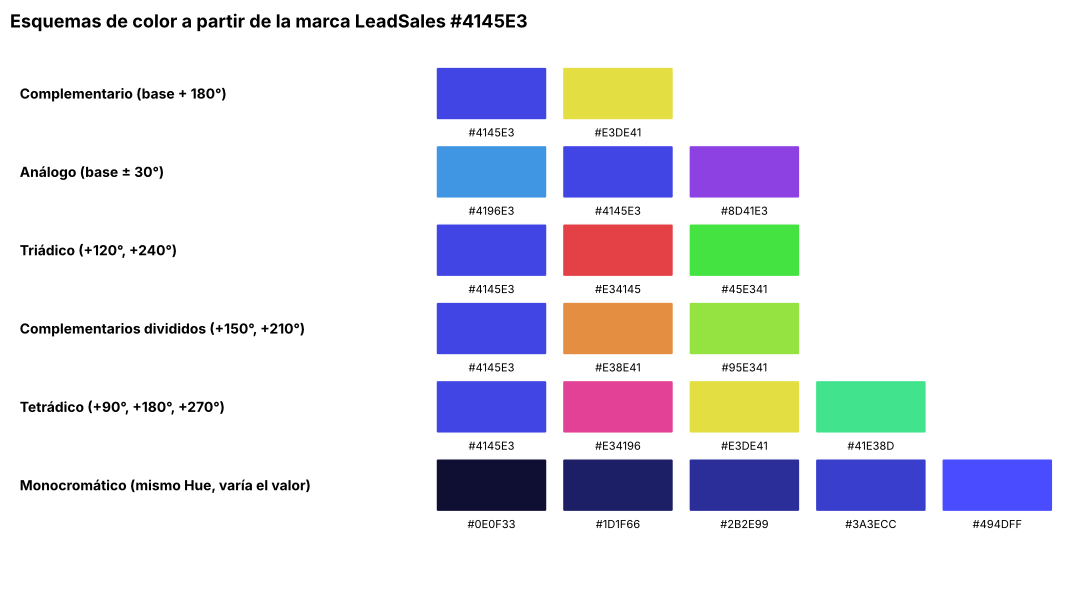

In [3]:
# =============================================================================
# Los 6 esquemas de la clase, aplicados al color de LeadSales
# =============================================================================
ESQUEMAS = {
    "Complementario (base + 180°)": [BASE, rotar_tono(BASE, 180)],
    "Análogo (base ± 30°)": [rotar_tono(BASE, -30), BASE, rotar_tono(BASE, 30)],
    "Triádico (+120°, +240°)": [BASE, rotar_tono(BASE, 120), rotar_tono(BASE, 240)],
    "Complementarios divididos (+150°, +210°)": [BASE, rotar_tono(BASE, 150), rotar_tono(BASE, 210)],
    "Tetrádico (+90°, +180°, +270°)": [BASE, rotar_tono(BASE, 90), rotar_tono(BASE, 180), rotar_tono(BASE, 270)],
    "Monocromático (mismo Hue, varía el valor)": [hsv_to_hex(h, s, (i + 1) / 5) for i in range(5)],
}

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 11); ax.set_ylim(0, 6.6); ax.axis("off")
ax.set_title(f"Esquemas de color a partir de la marca LeadSales {BASE}", fontsize=13, fontweight="bold", loc="left")
y = 5.6
for nombre, colores in ESQUEMAS.items():
    ax.text(0.1, y + 0.3, nombre, fontsize=10, fontweight="bold", va="center")
    x = 4.4
    for c in colores:
        ax.add_patch(patches.FancyBboxPatch((x, y), 1.1, 0.6, boxstyle="round,pad=0.02",
                                            facecolor=c, edgecolor="white"))
        ax.text(x + 0.55, y - 0.22, c, ha="center", fontsize=8)
        x += 1.3
    y -= 0.95
plt.tight_layout(); plt.show()

### 1.3 La paleta elegida y la regla 60-30-10

| Rol | Color | De dónde sale | Dónde se usa en el tablero |
|---|---|---|---|
| **60 % · Fondo** | `#F5F6FA` (fondo) y `#FFFFFF` (tarjetas) | Neutros: no compiten con los datos | Fondo de la página y de cada tarjeta |
| **30 % · Marca** | `#4145E3` | Color base de LeadSales | Menú lateral activo, títulos, valores de los KPI y la serie "de referencia" en las gráficas |
| **10 % · Acento / CTA** | `#E3DE41` | **Complementario** (base + 180°) | *Solo* en los botones de acción: "Descargar lista de revisión" y "Ver perfil" |
| Escala de datos | Tintes y sombras de `#4145E3` | **Monocromático** | Gráficas ordenadas de menor a mayor (deciles de riesgo, segmentos) |

**Colores semánticos** (no se reparten en el 60-30-10; respetan lo que el usuario ya aprendió):

| Significado | Color | Uso en el tablero |
|---|---|---|
| Riesgo / error | `#DC2626` | Cuentas con la señal de riesgo, "Canceló", alertas |
| Éxito | `#16A34A` | "Sigue activa", mejoras |
| Advertencia | `#C2410C` | Avisos, perfil de uso nulo y estado vacío. Empezamos con `#EA580C`, pero la prueba de contraste (1.4) mostró que con texto blanco no pasaba (3.6:1); el mismo naranja más oscuro sí pasa (5.2:1) |
| Texto principal | `#202B37` | Títulos y párrafos (el mismo del sitio de LeadSales) |
| Texto secundario | `#637083` | Notas, ejes y fuentes |

**Por qué la advertencia es naranja y no amarilla:** el complementario de nuestra marca ya es amarillo. Si la advertencia también fuera amarilla, el botón de acción y los avisos se confundirían y el acento dejaría de ser único.

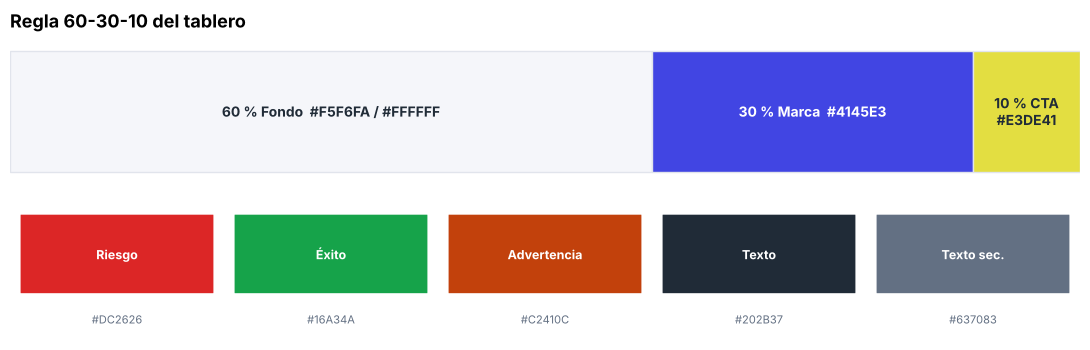

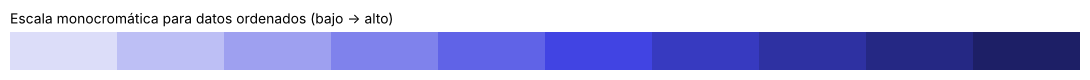

In [4]:
# =============================================================================
# Paleta del tablero (un solo lugar: si la marca cambia, se cambia aquí y todo se actualiza)
# =============================================================================
PALETA = {
    "fondo": "#F5F6FA",          # 60 %
    "superficie": "#FFFFFF",     # 60 % (tarjetas)
    "marca": BASE,               # 30 %
    "acento": rotar_tono(BASE, 180),   # 10 % (complementario)
    "error": "#DC2626",
    "exito": "#16A34A",
    "advertencia": "#C2410C",   # antes #EA580C: no pasaba WCAG con texto blanco (ver 1.4)
    "texto": "#202B37",
    "texto_sec": "#637083",
    "borde": "#E1E4EC",
}
# Escala monocromática para datos ordenados: de un tinte claro a una sombra oscura de la marca
ESCALA_MARCA = [mezclar("#FFFFFF", BASE, t) for t in np.linspace(0.18, 1, 6)] + \
               [mezclar(BASE, "#000000", t) for t in np.linspace(0.15, 0.55, 4)]

# --- Muestra visual de la regla 60-30-10 ---
fig, axes = plt.subplots(2, 1, figsize=(11, 3.6), gridspec_kw={"height_ratios": [1.1, 1]})
ax = axes[0]; ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 1)
ax.set_title("Regla 60-30-10 del tablero", loc="left", fontsize=13, fontweight="bold")
izq = 0
for ancho, color, texto, color_txt in [(60, PALETA["fondo"], "60 % Fondo  #F5F6FA / #FFFFFF", PALETA["texto"]),
                                       (30, PALETA["marca"], "30 % Marca  #4145E3", "white"),
                                       (10, PALETA["acento"], "10 % CTA\n#E3DE41", PALETA["texto"])]:
    ax.add_patch(patches.Rectangle((izq, 0.1), ancho, 0.8, facecolor=color, edgecolor=PALETA["borde"]))
    ax.text(izq + ancho / 2, 0.5, texto, ha="center", va="center", fontsize=10, color=color_txt, fontweight="bold")
    izq += ancho
ax = axes[1]; ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 1)
semanticos = [("Riesgo", "error"), ("Éxito", "exito"), ("Advertencia", "advertencia"),
              ("Texto", "texto"), ("Texto sec.", "texto_sec")]
for i, (nombre, clave) in enumerate(semanticos):
    x0 = i * 20 + 1
    ax.add_patch(patches.FancyBboxPatch((x0, 0.35), 18, 0.55, boxstyle="round,pad=0.01",
                                        facecolor=PALETA[clave], edgecolor="none"))
    ax.text(x0 + 9, 0.62, nombre, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(x0 + 9, 0.12, PALETA[clave], ha="center", fontsize=8, color=PALETA["texto_sec"])
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 0.9))
ax.axis("off"); ax.set_xlim(0, len(ESCALA_MARCA)); ax.set_ylim(0, 1)
ax.set_title("Escala monocromática para datos ordenados (bajo → alto)", loc="left", fontsize=10)
for i, c in enumerate(ESCALA_MARCA):
    ax.add_patch(patches.Rectangle((i, 0), 1, 1, facecolor=c))
plt.tight_layout(); plt.show()

### 1.4 Prueba de contraste (WCAG 2.1)
Texto normal necesita **4.5:1**; títulos y texto grande, **3:1**. Revisamos cada combinación que usa el tablero.

In [5]:
# =============================================================================
# Prueba de contraste de todas las combinaciones de texto y fondo del tablero
# =============================================================================
combinaciones = [
    ("Texto principal sobre fondo", PALETA["texto"], PALETA["fondo"], 4.5),
    ("Texto secundario sobre tarjeta", PALETA["texto_sec"], PALETA["superficie"], 4.5),
    ("Valor del KPI (marca) sobre tarjeta", PALETA["marca"], PALETA["superficie"], 3.0),
    ("Texto blanco sobre marca (menú activo)", "#FFFFFF", PALETA["marca"], 4.5),
    ("Texto oscuro sobre acento (botón CTA)", PALETA["texto"], PALETA["acento"], 4.5),
    ("Texto blanco sobre acento (NO usar)", "#FFFFFF", PALETA["acento"], 4.5),
    ("Texto blanco sobre riesgo (etiqueta)", "#FFFFFF", PALETA["error"], 4.5),
    ("Texto riesgo sobre tarjeta", PALETA["error"], PALETA["superficie"], 4.5),
    ("Texto blanco sobre advertencia (etiqueta)", "#FFFFFF", PALETA["advertencia"], 4.5),
    ("Texto blanco sobre el naranja anterior #EA580C (descartado)", "#FFFFFF", "#EA580C", 4.5),
    ("Texto blanco sobre éxito (solo títulos)", "#FFFFFF", PALETA["exito"], 3.0),
]
tabla_contraste = pd.DataFrame([
    {"Combinación": n, "Texto": t, "Fondo": f, "Contraste": round(contraste(t, f), 2), "Mínimo": m,
     "¿Pasa?": "Sí" if contraste(t, f) >= m else "No"}
    for n, t, f, m in combinaciones
])
display(tabla_contraste)

,Combinación,Texto,Fondo,Contraste,Mínimo,¿Pasa?
0,Texto principal sobre fondo,#202B37,#F5F6FA,13.30,4.5,Sí
1,Texto secundario sobre tarjeta,#637083,#FFFFFF,5.03,4.5,Sí
2,Valor del KPI (marca) sobre tarjeta,#4145E3,#FFFFFF,6.59,3.0,Sí
3,Texto blanco sobre marca (menú activo),#FFFFFF,#4145E3,6.59,4.5,Sí
4,Texto oscuro sobre acento (botón CTA),#202B37,#E3DE41,10.12,4.5,Sí
5,Texto blanco sobre acento (NO usar),#FFFFFF,#E3DE41,1.42,4.5,No
6,Texto blanco sobre riesgo (etiqueta),#FFFFFF,#DC2626,4.83,4.5,Sí
7,Texto riesgo sobre tarjeta,#DC2626,#FFFFFF,4.83,4.5,Sí
8,Texto blanco sobre advertencia (etiqueta),#FFFFFF,#C2410C,5.18,4.5,Sí
9,Texto blanco sobre el naranja anterior #EA580C (descartado),#FFFFFF,#EA580C,3.56,4.5,No


**Lectura:** todas las combinaciones que usa el tablero pasan. El acento amarillo **solo funciona con texto oscuro** (10.1:1); con texto blanco no se leería (1.4:1), por eso los botones CTA llevan texto `#202B37`. El verde de éxito con texto blanco solo pasa para títulos grandes, así que en texto normal lo usamos como color del texto sobre fondo blanco o como ícono. Las dos filas que dicen "No" son combinaciones que **no usamos**: el blanco sobre amarillo y el naranja original `#EA580C`, que cambiamos por `#C2410C` precisamente por esta prueba.

**Psicología del color:** el azul-violeta transmite **confianza y tecnología** (lo que vende LeadSales) y es tranquilo para un tablero que se consulta todos los días. El rojo se reserva para el **riesgo**: cuando aparece, significa "atiende esto". El amarillo del CTA es lo que más contrasta con la marca, así que el ojo va directo a la acción.

**Diseñar con sistemas, no con colores sueltos:** toda la paleta sale de `BASE`. Si LeadSales cambiara su color mañana, basta con cambiar ese valor y volver a ejecutar: los esquemas, el acento complementario, la escala y las gráficas se actualizan solos.

In [6]:
# =============================================================================
# Estilo de todas las gráficas del tablero, a partir de la paleta
# =============================================================================
plt.rcParams.update({
    "figure.facecolor": PALETA["superficie"],
    "axes.facecolor": PALETA["superficie"],
    "axes.edgecolor": PALETA["borde"],
    "axes.labelcolor": PALETA["texto_sec"],
    "axes.titlecolor": PALETA["texto"],
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.axisbelow": True,            # la cuadrícula va detrás de las barras
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": PALETA["borde"],
    "grid.linewidth": 0.8,
    "xtick.color": PALETA["texto_sec"],
    "ytick.color": PALETA["texto_sec"],
    "text.color": PALETA["texto"],
    "font.size": 10,
    "legend.frameon": False,
})


def subtitulo(ax, texto):
    # Línea gris debajo del título con la lectura de la gráfica
    ax.text(0, 1.02, texto, transform=ax.transAxes, fontsize=9.5, color=PALETA["texto_sec"], va="bottom")


def fuente(fig, texto="Fuente: datos v3 de LeadSales (corte 31-oct-2026). Elaboración: Equipo Teky."):
    fig.text(0.01, 0.005, texto, fontsize=7.5, color=PALETA["texto_sec"])


print("Estilo aplicado")

Estilo aplicado


---
# 2. Datos

Usamos cuatro archivos del paquete **v3** (corte 31-oct-2026):

| Archivo | Una fila es… | Para qué lo usamos |
|---|---|---|
| `panel_mensual.csv` | Una cuenta en un mes | Uso (chats, mensajes, días activos), plan, mora y tickets |
| `perfil_cuentas.csv` | Una cuenta | Fecha de alta y **fecha de baja** (el desenlace) |
| `cancelaciones.csv` | Una respuesta de la encuesta de salida | Motivo de cancelación |
| `historial_canales_eventos.csv` | Una conexión o desconexión de un canal | Estado de WhatsApp Web al cierre de cada mes |

Los archivos se leen del repositorio del equipo en GitHub. Si el notebook se ejecuta dentro del repositorio, usa la carpeta `datos/` local.

In [7]:
# =============================================================================
# Carga de datos: carpeta local datos/ si existe; si no, el repositorio público en GitHub
# =============================================================================
URL_DATOS = "https://raw.githubusercontent.com/AnneliseSpears/-proyecto-integrador-equipoTeki/main/datos"
CARPETA_LOCAL = Path("datos")


def ruta(nombre):
    local = CARPETA_LOCAL / nombre
    return local if local.exists() else f"{URL_DATOS}/{nombre}"


panel = pd.read_csv(ruta("panel_mensual.csv"), parse_dates=["mes"])
perfil = pd.read_csv(ruta("perfil_cuentas.csv"), parse_dates=["fecha_inicio", "fecha_baja"])
cancelaciones = pd.read_csv(ruta("cancelaciones.csv"), parse_dates=["fecha"])
eventos = pd.read_csv(ruta("historial_canales_eventos.csv"), parse_dates=["fecha_hora"])

for nombre, df in [("panel_mensual", panel), ("perfil_cuentas", perfil),
                   ("cancelaciones", cancelaciones), ("historial_canales_eventos", eventos)]:
    print(f"{nombre:28s} {df.shape[0]:>7,} filas · {df.shape[1]:>2} columnas")
print("\nEstados de las cuentas al 31-oct:", perfil["estado"].value_counts().to_dict())

panel_mensual                 23,226 filas · 20 columnas
perfil_cuentas                 3,526 filas · 28 columnas
cancelaciones                  1,098 filas · 10 columnas
historial_canales_eventos     50,393 filas ·  5 columnas

Estados de las cuentas al 31-oct: {'activa': 2059, 'baja': 1467}


### 2.1 Preparación: una fila por cuenta activa al cierre de cada mes

Para decir que algo **anticipa** la cancelación, miramos a cada cuenta **activa al cierre de un mes** (el *corte*), calculamos cómo venía usando LeadSales en los 3 meses previos y revisamos si canceló en los **60 días siguientes**. Es la misma población de la Evidencia 4:

- la cuenta lleva **3 meses seguidos activa** y pagando desde el inicio de la ventana;
- el desenlace solo se conoce si ya pasaron los 60 días (mayo a agosto). Septiembre y octubre no tienen desenlace todavía: son "las cuentas de hoy" que hay que priorizar.

In [8]:
# =============================================================================
# Variables de uso por cuenta y mes (ventana de 3 meses)
# =============================================================================
panel = panel.sort_values(["account_id", "mes"]).reset_index(drop=True)
panel = panel.merge(perfil[["account_id", "fecha_inicio", "fecha_baja"]], on="account_id", how="left")
panel["prop_dias_activos"] = panel["dias_activos"] / panel["mes"].dt.days_in_month

por_cuenta = panel.groupby("account_id")
for k in (1, 2):   # valores de 1 y 2 meses antes
    panel[f"mes_prev{k}"] = por_cuenta["mes"].shift(k)
    panel[f"estado_prev{k}"] = por_cuenta["estado_en_mes"].shift(k)
    panel[f"chats_prev{k}"] = por_cuenta["n_chats"].shift(k)
    panel[f"dias_prev{k}"] = por_cuenta["dias_activos"].shift(k)
    panel[f"tickets_prev{k}"] = por_cuenta["n_tickets_soporte"].shift(k)
    panel[f"prop_prev{k}"] = por_cuenta["prop_dias_activos"].shift(k)

# Ventana válida: 3 meses consecutivos, activa en los 2 previos y pagando desde el inicio de la ventana
panel["ventana_completa"] = (
    (panel["mes_prev1"] == panel["mes"] - pd.DateOffset(months=1))
    & (panel["mes_prev2"] == panel["mes"] - pd.DateOffset(months=2))
    & (panel["estado_prev1"] == "activa") & (panel["estado_prev2"] == "activa")
    & (panel["fecha_inicio"] <= panel["mes"] - pd.DateOffset(months=2))
)

chats3 = panel[["chats_prev2", "chats_prev1", "n_chats"]].astype(float)
base_chats = (panel["chats_prev1"] + panel["chats_prev2"]) / 2
medible = panel["ventana_completa"] & (base_chats > 0)   # si el promedio previo es 0, la caída no se puede medir

# --- Señales de USO (las que usa el tablero) ---
panel["caida_50"] = np.where(medible, (panel["n_chats"] / base_chats <= 0.5).astype(float), np.nan)
panel["variacion_chats_%"] = np.where(medible, (panel["n_chats"] / base_chats - 1) * 100, np.nan)
panel["uso_bajo_dias_2m"] = np.where(panel["ventana_completa"],
                                     ((panel["prop_dias_activos"] < .5) & (panel["prop_prev1"] < .5)).astype(float), np.nan)
panel["nivel_adopcion"] = pd.cut(panel["prop_dias_activos"], [-.01, .25, .75, 1.01],
                                 labels=["Baja (<25 % de días)", "Media (25–75 %)", "Alta (>75 %)"]).astype(str)

# --- Señales de CONTEXTO ---
panel["mora"] = panel["en_morosidad"].astype(float)
panel["tickets_3m"] = np.where(panel["ventana_completa"],
                               ((panel["n_tickets_soporte"] + panel["tickets_prev1"] + panel["tickets_prev2"]) > 0).astype(float), np.nan)

# --- Variables del modelo de la Evidencia 4 (bloque USO, 11 variables) ---
panel["chats_ultimo_mes"] = panel["n_chats"]
panel["mensajes_ultimo_mes"] = panel["n_mensajes"]
panel["media_chats_3m"] = chats3.mean(axis=1, skipna=False)
panel["tendencia_chats_3m"] = (panel["n_chats"] - panel["chats_prev2"]) / 2
panel["volatilidad_chats_3m"] = chats3.std(axis=1, ddof=0, skipna=False)
panel["cambio_relativo_chats"] = np.where(panel["chats_prev1"] > 0, panel["n_chats"] / panel["chats_prev1"] - 1, np.nan)
panel["caida_chats_50pct"] = panel["caida_50"]
panel["uso_bajo_2m"] = ((panel["n_chats"] < 10) & (panel["chats_prev1"] < 10)).astype(float)

# --- Variables de adopción para K-Means (las 4 de la Evidencia 4) ---
log3 = np.log1p(chats3)
panel["log_chats_promedio_3m"] = np.log1p(panel["media_chats_3m"])
panel["prop_dias_activos_3m"] = (panel["dias_activos"] + panel["dias_prev1"] + panel["dias_prev2"]) / 92
panel["cambio_log_chats_3m"] = np.log1p(panel["n_chats"]) - np.log1p(panel["chats_prev2"])
panel["variabilidad_log_chats_3m"] = log3.std(axis=1, ddof=0)
print("Variables calculadas:", panel.shape)

Variables calculadas: (23226, 54)


In [9]:
# =============================================================================
# Canal: estado de WhatsApp Web al cierre de cada mes (reglas de la Evidencia 4)
# =============================================================================
def estado_whatsapp(eventos, consultas):
    # - solo cuentan los eventos hasta el día del corte
    # - una desconexión de menos de 24 h al corte queda como "Desconocido" (puede ser un parpadeo)
    # - si en el mismo instante hay conecta y desconecta, el estado es "Desconocido"
    # - sin eventos en el periodo = la cuenta no usa WhatsApp Web (p. ej. usa la API)
    # Solo usamos WhatsApp Web: Instagram, Facebook y la API tienen desconexiones faltantes y borrados masivos.
    wa = eventos[eventos["canal"] == "whatsapp_web"].copy()
    wa["fecha_hora"] = pd.to_datetime(wa["fecha_hora"], utc=True).dt.tz_localize(None).astype("datetime64[ns]")
    wa["valor"] = wa["evento"].map({"conecta": 1, "conectado_al_inicio": 1, "desconecta": 0})
    wa = wa.groupby(["account_id", "fecha_hora"], as_index=False)["valor"].agg(["min", "max"])
    wa["valor"] = np.where(wa["min"] == wa["max"], wa["min"], -1)
    wa = wa.sort_values("fecha_hora")[["account_id", "fecha_hora", "valor"]]

    consultas = consultas.drop_duplicates().copy()
    consultas["limite"] = (consultas["corte"] + pd.Timedelta(days=1)).astype("datetime64[ns]")
    consultas = consultas.sort_values("limite")
    ultimo = pd.merge_asof(consultas, wa, left_on="limite", right_on="fecha_hora", by="account_id")
    reciente = (ultimo["limite"] - ultimo["fecha_hora"]) < pd.Timedelta(hours=24)
    ultimo["estado_wa"] = np.select(
        [ultimo["valor"].isna(), ultimo["valor"] == -1, ultimo["valor"] == 1, reciente],
        ["Sin WhatsApp Web", "Desconocido", "Conectado", "Desconocido"], default="Desconectado")
    return ultimo[["account_id", "corte", "estado_wa"]]


# =============================================================================
# Base del tablero: cuentas activas al cierre de cada mes, con su desenlace a 60 días
# =============================================================================
base = panel[(panel["estado_en_mes"] == "activa") & panel["ventana_completa"]
             & (panel["mes"] >= pd.Timestamp("2026-05-01"))].copy()
base["corte"] = base["mes"] + pd.offsets.MonthEnd(0)
base = base[base["fecha_baja"].isna() | (base["fecha_baja"] > base["corte"])]
base["antiguedad_dias"] = (base["corte"] - base["fecha_inicio"]).dt.days

fin_ventana = base["corte"] + pd.Timedelta(days=HORIZONTE_DIAS)
cancelo = (base["fecha_baja"] > base["corte"]) & (base["fecha_baja"] <= fin_ventana)
base["churn_60d"] = np.where(fin_ventana <= CORTE_DATOS, cancelo.astype(float), np.nan)   # NaN = aún sin desenlace

base = base.merge(estado_whatsapp(eventos, base[["account_id", "corte"]]), on=["account_id", "corte"], how="left")
base["wa_desconectado"] = base["estado_wa"].map({"Desconectado": 1.0, "Conectado": 0.0})
base = base.sort_values(["corte", "account_id"]).reset_index(drop=True)
con_desenlace = base[base["churn_60d"].notna()]

# Validación: mismas cuentas y bajas que la Evidencia 4 (2,046 / 213 en mayo; 2,079 / 229 en agosto)
resumen = base.groupby("corte").agg(cuentas=("account_id", "size"), bajas_60d=("churn_60d", "sum"),
                                    tasa_churn_pct=("churn_60d", "mean"))
resumen["tasa_churn_pct"] = (resumen["tasa_churn_pct"] * 100).round(2)
resumen.index = [etiqueta_mes(c) for c in resumen.index]
display(resumen)

,cuentas,bajas_60d,tasa_churn_pct
May 2026,2046,213.0,10.41
Jun 2026,2058,220.0,10.69
Jul 2026,2062,212.0,10.28
Ago 2026,2079,229.0,11.01
Sep 2026,2092,0.0,NaN
Oct 2026,2059,0.0,NaN


---
# 3. Modelos de la Evidencia 4

En la Evidencia 4 elegimos dos modelos. Aquí los **reentrenamos con la misma configuración y la misma semilla** para que el tablero use sus resultados:

| Modelo | Para qué sirve en el tablero | Configuración (Evidencia 4) |
|---|---|---|
| **Extra Trees calibrado** (supervisado) | **Score de riesgo**: ordena las cuentas activas para que Customer Success revise primero a las más riesgosas | 11 variables de uso · 250 árboles, profundidad 8, hoja mínima 10, pesos balanceados · calibración sigmoid · umbral por F2 |
| **K-Means, K = 3** (no supervisado) | **Perfiles de adopción**: decide qué acción ofrecer a cada cuenta | 4 variables de adopción estandarizadas · k-means++ con 30 inicios |

**Validación temporal (igual que la Evidencia 4):** se entrena con el corte de **mayo** (60 % entrenamiento, 20 % validación, 20 % calibración) y se evalúa una sola vez con el corte de **agosto**, cuyo desenlace ocurrió después.

In [10]:
# =============================================================================
# 3.1 Score de riesgo: Extra Trees con las 11 variables de uso
# =============================================================================
VARIABLES_USO = ["plan", "antiguedad_dias", "chats_ultimo_mes", "mensajes_ultimo_mes", "prop_dias_activos",
                 "media_chats_3m", "tendencia_chats_3m", "volatilidad_chats_3m", "cambio_relativo_chats",
                 "caida_chats_50pct", "uso_bajo_2m"]


def hacer_pipeline(columnas, modelo):
    # Imputación (mediana + indicador de faltante) y one-hot del plan. Todo se aprende solo con entrenamiento.
    numericas = [c for c in columnas if c != "plan"]
    preparar = ColumnTransformer([
        ("numericas", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), numericas),
        ("plan", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                           ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ["plan"]),
    ])
    return Pipeline([("preparar", preparar), ("modelo", modelo)])


desarrollo = base[base["corte"] == CORTE_MAYO].sort_values("account_id").reset_index(drop=True)
prueba = base[base["corte"] == CORTE_AGOSTO].sort_values("account_id").reset_index(drop=True)
y_desarrollo = desarrollo["churn_60d"].astype(int)

i_train, i_resto = train_test_split(np.arange(len(desarrollo)), test_size=.4, random_state=SEMILLA, stratify=y_desarrollo)
i_val, i_cal = train_test_split(i_resto, test_size=.5, random_state=SEMILLA, stratify=y_desarrollo.iloc[i_resto])
train, val, cal = desarrollo.iloc[i_train], desarrollo.iloc[i_val], desarrollo.iloc[i_cal]
y_train, y_val, y_cal = (d["churn_60d"].astype(int).to_numpy() for d in (train, val, cal))

extra_trees = hacer_pipeline(VARIABLES_USO, ExtraTreesClassifier(
    n_estimators=250, max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=SEMILLA, n_jobs=-1))
extra_trees.fit(train[VARIABLES_USO], y_train)

# Calibración: los pesos balanceados inflan las probabilidades; la calibración las regresa a una escala real
modelo_riesgo = CalibratedClassifierCV(FrozenEstimator(extra_trees), method="sigmoid").fit(cal[VARIABLES_USO], y_cal)

# Umbral de alerta: el que maximiza F2 en validación (pesa el doble no perder una baja que una llamada de más)
prob_val = modelo_riesgo.predict_proba(val[VARIABLES_USO])[:, 1]
umbrales = np.linspace(.01, .99, 197)
f2 = [fbeta_score(y_val, (prob_val >= u).astype(int), beta=2, zero_division=0) for u in umbrales]
UMBRAL = float(umbrales[int(np.argmax(f2))])

tabla_split = pd.DataFrame({"cuentas": [len(train), len(val), len(cal), len(prueba)],
                            "bajas": [y_train.sum(), y_val.sum(), y_cal.sum(), int(prueba["churn_60d"].sum())]},
                           index=["entrenamiento (may)", "validación (may)", "calibración (may)", "prueba (ago)"])
display(tabla_split)
print(f"AP en validación: {average_precision_score(y_val, prob_val):.3f} · umbral F2 elegido: {UMBRAL:.3f}")

,cuentas,bajas
entrenamiento (may),1227,128
validación (may),409,42
calibración (may),410,43
prueba (ago),2079,229


AP en validación: 0.278 · umbral F2 elegido: 0.095


In [11]:
# =============================================================================
# 3.2 Evaluación final en agosto (una sola vez, con todo congelado)
# =============================================================================
y_test = prueba["churn_60d"].astype(int).to_numpy()
prueba["score"] = modelo_riesgo.predict_proba(prueba[VARIABLES_USO])[:, 1]
alerta = (prueba["score"] >= UMBRAL).astype(int)

metricas_prueba = pd.Series({
    "Average Precision (AP)": average_precision_score(y_test, prueba["score"]),
    "Referencia de azar (prevalencia)": y_test.mean(),
    "ROC-AUC": roc_auc_score(y_test, prueba["score"]),
    "Recall con umbral F2": recall_score(y_test, alerta),
    "Precisión con umbral F2": precision_score(y_test, alerta),
}).round(3)
display(metricas_prueba.to_frame("Prueba agosto"))
print("Evidencia 4 reportó para Extra Trees: AP 0.199 · ROC-AUC 0.676 · recall 0.559")

,Prueba agosto
Average Precision (AP),0.199
Referencia de azar (prevalencia),0.110
ROC-AUC,0.676
Recall con umbral F2,0.559
Precisión con umbral F2,0.193


Evidencia 4 reportó para Extra Trees: AP 0.199 · ROC-AUC 0.676 · recall 0.559


In [12]:
# =============================================================================
# 3.3 Score de las cuentas de HOY (corte 31-oct): aún sin desenlace, es la lista a priorizar
# =============================================================================
hoy = base[base["corte"] == CORTE_HOY].copy()
hoy["score"] = modelo_riesgo.predict_proba(hoy[VARIABLES_USO])[:, 1]
# Decil 1 = el 10 % con mayor score
hoy["decil_riesgo"] = pd.qcut(hoy["score"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
prueba["decil_riesgo"] = pd.qcut(prueba["score"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
print(f"Cuentas activas al {CORTE_HOY.date()}: {len(hoy):,} · en el decil 1 (prioridad): {(hoy['decil_riesgo'] == 1).sum():,}")
print(f"Score promedio del decil 1: {hoy.loc[hoy['decil_riesgo'] == 1, 'score'].mean():.1%} · del resto: "
      f"{hoy.loc[hoy['decil_riesgo'] > 1, 'score'].mean():.1%}")

Cuentas activas al 2026-10-31: 2,059 · en el decil 1 (prioridad): 206
Score promedio del decil 1: 28.5% · del resto: 8.5%


In [13]:
# =============================================================================
# 3.4 Perfiles de adopción: K-Means (K = 3) con las 4 variables de la Evidencia 4
# =============================================================================
VARS_SEG = ["log_chats_promedio_3m", "prop_dias_activos_3m", "cambio_log_chats_3m", "variabilidad_log_chats_3m"]
NOMBRES_SEG = {0: "Uso muy bajo o nulo", 1: "Descenso de actividad", 2: "Uso estable"}

seg_agosto = prueba.copy()                          # ventana jun–ago, las mismas 2,079 cuentas
escalador = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
X_seg = escalador.fit_transform(seg_agosto[VARS_SEG])

# Revisión rápida de K. La Evidencia 4 eligió K=3: mejor silueta entre las opciones cuyo grupo más chico
# tiene al menos 5 % de las cuentas (un grupo de 2 % no sirve para una estrategia).
revision_k = []
for k in range(2, 6):
    etiquetas_k = KMeans(n_clusters=k, n_init=30, max_iter=500, random_state=SEMILLA).fit_predict(X_seg)
    revision_k.append({"K": k, "silueta": round(silhouette_score(X_seg, etiquetas_k), 3),
                       "grupo_más_chico_%": round(pd.Series(etiquetas_k).value_counts(normalize=True).min() * 100, 1)})
display(pd.DataFrame(revision_k))

kmeans = KMeans(n_clusters=3, init="k-means++", n_init=30, max_iter=500, random_state=SEMILLA).fit(X_seg)

# Renumeramos por nivel de uso (0 = el que menos chatea). El número no significa riesgo.
orden_uso = pd.Series(seg_agosto["media_chats_3m"].to_numpy()).groupby(kmeans.labels_).mean().sort_values().index
MAPA_GRUPO = {g: i for i, g in enumerate(orden_uso)}


def asignar_segmento(df):
    # Usa el MISMO escalador y los MISMOS centroides de agosto: sirve para cuentas nuevas o cortes nuevos
    grupos = kmeans.predict(escalador.transform(df[VARS_SEG]))
    return pd.Series([NOMBRES_SEG[MAPA_GRUPO[g]] for g in grupos], index=df.index)


seg_agosto["segmento"] = asignar_segmento(seg_agosto)
prueba["segmento"] = seg_agosto["segmento"]
hoy["segmento"] = asignar_segmento(hoy)          # ventana ago–oct: perfiles de HOY

perfil_seg = seg_agosto.groupby("segmento").agg(
    cuentas=("account_id", "size"), chats_mediana=("media_chats_3m", "median"),
    dias_activos_mediana=("prop_dias_activos_3m", "median"), churn_60d_pct=("churn_60d", "mean"))
perfil_seg["churn_60d_pct"] = (perfil_seg["churn_60d_pct"] * 100).round(1)
display(perfil_seg.round(2))
print("Evidencia 4: estable 8.7 % · uso nulo 19.5 % · descenso 37.7 %")

,K,silueta,grupo_más_chico_%
0,2,0.701,13.5
1,3,0.731,5.1
2,4,0.737,2.2
3,5,0.374,2.0


,cuentas,chats_mediana,dias_activos_mediana,churn_60d_pct
segmento,,,,
Descenso de actividad,106,144.00,0.49,37.7
Uso estable,1809,711.67,1.00,8.7
Uso muy bajo o nulo,164,0.00,0.00,19.5


Evidencia 4: estable 8.7 % · uso nulo 19.5 % · descenso 37.7 %


In [14]:
# =============================================================================
# 3.5 ¿Qué variables explican el score? Importancia por permutación (en validación)
# =============================================================================
imp = permutation_importance(modelo_riesgo, val[VARIABLES_USO], y_val, scoring="average_precision",
                             n_repeats=10, random_state=SEMILLA, n_jobs=1)
importancia = (pd.DataFrame({"variable": VARIABLES_USO, "caida_AP": imp.importances_mean, "desv": imp.importances_std})
               .sort_values("caida_AP", ascending=False))
display(importancia.round(4).head(6))

,variable,caida_AP,desv
9,caida_chats_50pct,0.0791,0.0236
4,prop_dias_activos,0.0749,0.0272
0,plan,0.0570,0.0236
10,uso_bajo_2m,0.0354,0.0102
8,cambio_relativo_chats,0.0318,0.0097
1,antiguedad_dias,0.0290,0.0111


---
# 4. El tablero en 4 actos

Cada visual responde una pregunta que se hace la persona de **Customer Success** que abre el tablero. Las visuales están numeradas igual que en el prototipo de Figma (V1 a V14).

In [15]:
# =============================================================================
# Funciones auxiliares de las visuales
# =============================================================================
def wilson(bajas, n, z=1.96):
    # Intervalo de confianza de Wilson para una proporción (útil con grupos pequeños)
    p = bajas / n
    d = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / d
    radio = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return centro - radio, centro + radio


def etiquetas_barras(ax, barras, formato="{:.0f} %", color=None, dentro=False):
    # Escribe el valor encima (o dentro) de cada barra
    for b in barras:
        alto = b.get_height()
        y = alto - 1.2 if dentro else alto + 0.4
        ax.text(b.get_x() + b.get_width() / 2, y, formato.format(alto), ha="center",
                va="top" if dentro else "bottom", fontsize=9, fontweight="bold",
                color=color or PALETA["texto"])


COLOR_SEGMENTO = {"Uso estable": PALETA["marca"], "Uso muy bajo o nulo": PALETA["advertencia"],
                  "Descenso de actividad": PALETA["error"]}
print("Listo")

Listo


## Acto 1 · ¿Hay un problema?
*La persona de Customer Success abre el tablero y necesita saber, en cinco segundos, cuántas cuentas tiene, cuántas se le van y cuántas debe atender hoy.*

### V1 · Indicadores clave (4 KPI)

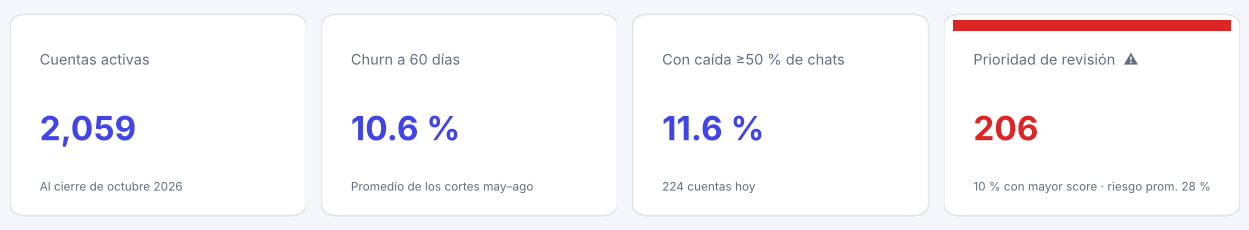

In [16]:
# =============================================================================
# V1 · Fila de indicadores
# =============================================================================
churn_prom = con_desenlace["churn_60d"].mean() * 100
caida_hoy = hoy["caida_50"].mean() * 100
prioridad_hoy = (hoy["decil_riesgo"] == 1).sum()
score_prioridad = hoy.loc[hoy["decil_riesgo"] == 1, "score"].mean() * 100

kpis = [
    ("Cuentas activas", f"{len(hoy):,}", "Al cierre de octubre 2026", PALETA["marca"], False),
    ("Churn a 60 días", f"{churn_prom:.1f} %", "Promedio de los cortes may–ago", PALETA["marca"], False),
    ("Con caída ≥50 % de chats", f"{caida_hoy:.1f} %", f"{int(hoy['caida_50'].sum()):,} cuentas hoy", PALETA["marca"], False),
    ("Prioridad de revisión", f"{prioridad_hoy:,}", f"10 % con mayor score · riesgo prom. {score_prioridad:.0f} %", PALETA["error"], True),
]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.4))
for ax, (titulo, valor, nota, color, alerta) in zip(axes, kpis):
    ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.add_patch(patches.FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="round,pad=0.02,rounding_size=0.06",
                                        facecolor=PALETA["superficie"], edgecolor=PALETA["borde"], linewidth=1.2))
    if alerta:
        ax.add_patch(patches.Rectangle((0.03, 0.9), 0.94, 0.05, facecolor=PALETA["error"], edgecolor="none"))
    ax.text(0.1, 0.74, titulo + ("  ⚠" if alerta else ""), fontsize=10.5, color=PALETA["texto_sec"])
    ax.text(0.1, 0.38, valor, fontsize=24, fontweight="bold", color=color)
    ax.text(0.1, 0.14, nota, fontsize=8.5, color=PALETA["texto_sec"])
fig.patch.set_facecolor(PALETA["fondo"])
plt.tight_layout(); plt.show()

### V2 · Ritmo de cancelación mes a mes

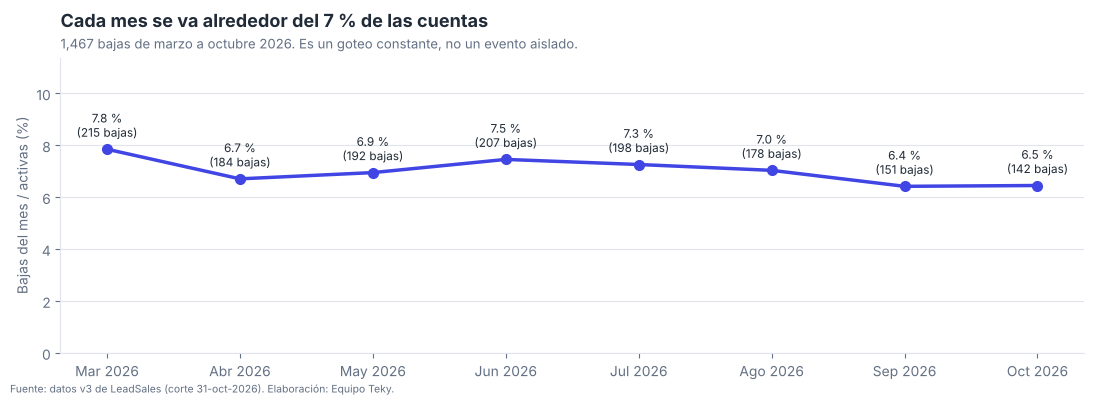

,activas,bajas,tasa_%
mes,,,
Mar 2026,2739,215,7.85
Abr 2026,2743,184,6.71
May 2026,2763,192,6.95
Jun 2026,2776,207,7.46
Jul 2026,2727,198,7.26
Ago 2026,2530,178,7.04
Sep 2026,2352,151,6.42
Oct 2026,2201,142,6.45


In [17]:
# =============================================================================
# V2 · Tasa mensual de bajas = bajas del mes / cuentas activas al inicio del mes (cohorte cerrada)
# =============================================================================
mensual = (panel[panel["estado_en_mes"].isin(["activa", "baja_este_mes"])]
           .groupby("mes")["estado_en_mes"].agg(activas="size", bajas=lambda s: (s == "baja_este_mes").sum()))
mensual["tasa_%"] = mensual["bajas"] / mensual["activas"] * 100

fig, ax = plt.subplots(figsize=(11, 4))
x = [etiqueta_mes(m) for m in mensual.index]
ax.plot(x, mensual["tasa_%"], color=PALETA["marca"], linewidth=2.5, marker="o", markersize=7)
for xi, (tasa, bajas) in zip(x, mensual[["tasa_%", "bajas"]].to_numpy()):
    ax.annotate(f"{tasa:.1f} %\n({int(bajas)} bajas)", (xi, tasa), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8.5, color=PALETA["texto"])
ax.set_ylim(0, mensual["tasa_%"].max() * 1.45)
ax.set_ylabel("Bajas del mes / activas (%)")
ax.set_title(f"Cada mes se va alrededor del {mensual['tasa_%'].mean():.0f} % de las cuentas", pad=22)
subtitulo(ax, f"{int(mensual['bajas'].sum()):,} bajas de marzo a octubre 2026. Es un goteo constante, no un evento aislado.")
fuente(fig); plt.tight_layout(); plt.show()
display(mensual.assign(**{"tasa_%": mensual["tasa_%"].round(2)}).rename(index=etiqueta_mes))

**Insight del acto 1:** la cartera pierde cerca del **7 % de sus cuentas cada mes** (entre 6.4 % y 7.9 %) y, entre las cuentas con 3 meses de historial, **1 de cada 10 cancela en los 60 días siguientes**. Es un goteo constante: si Customer Success espera a que la cuenta pida la baja, ya es tarde. La pregunta es si hay señales **antes**.

## Acto 2 · ¿Qué lo anticipa?
*Aquí se contesta la pregunta directiva: ¿la baja adopción de funcionalidades (uso) y de canales aparece antes de cancelar?*

### V3 · La caída de uso, mes por mes

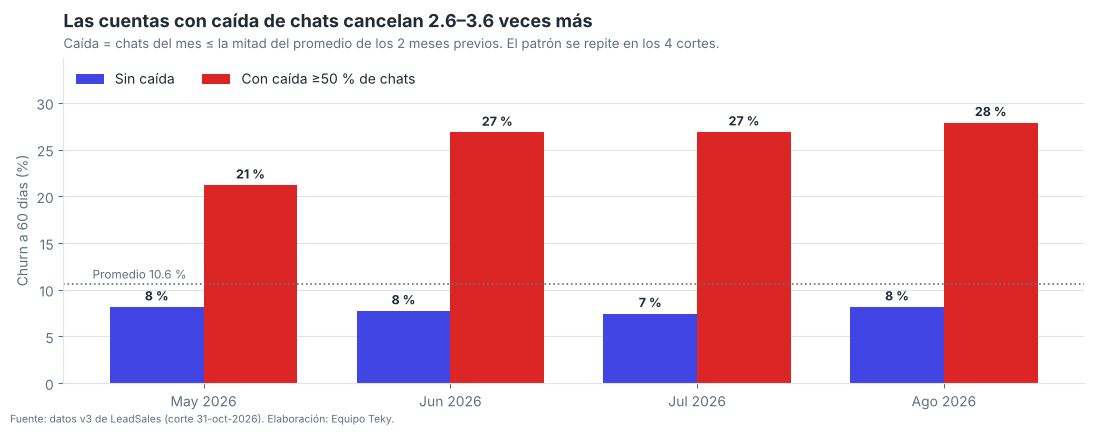

In [18]:
# =============================================================================
# V3 · Churn a 60 días de las cuentas con caída ≥50 % de chats vs sin caída, por corte
# =============================================================================
t = (con_desenlace.dropna(subset=["caida_50"]).groupby(["corte", "caida_50"])["churn_60d"].mean().unstack() * 100)
fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(len(t)); ancho = 0.38
b1 = ax.bar(x - ancho / 2, t[0.0], ancho, color=PALETA["marca"], label="Sin caída")
b2 = ax.bar(x + ancho / 2, t[1.0], ancho, color=PALETA["error"], label="Con caída ≥50 % de chats")
etiquetas_barras(ax, b1); etiquetas_barras(ax, b2)
ax.axhline(churn_prom, color=PALETA["texto_sec"], linestyle=":", linewidth=1.2)
ax.text(-0.45, churn_prom + 0.6, f"Promedio {churn_prom:.1f} %", ha="left", fontsize=8.5, color=PALETA["texto_sec"])
ax.set_xticks(x, [etiqueta_mes(c) for c in t.index]); ax.set_ylabel("Churn a 60 días (%)")
ax.set_ylim(0, t.max().max() * 1.25)
veces = (t[1.0] / t[0.0])
ax.set_title(f"Las cuentas con caída de chats cancelan {veces.min():.1f}–{veces.max():.1f} veces más", pad=22)
subtitulo(ax, "Caída = chats del mes ≤ la mitad del promedio de los 2 meses previos. El patrón se repite en los 4 cortes.")
ax.legend(loc="upper left", ncols=2); fuente(fig); plt.tight_layout(); plt.show()

### V4 · La frecuencia de uso

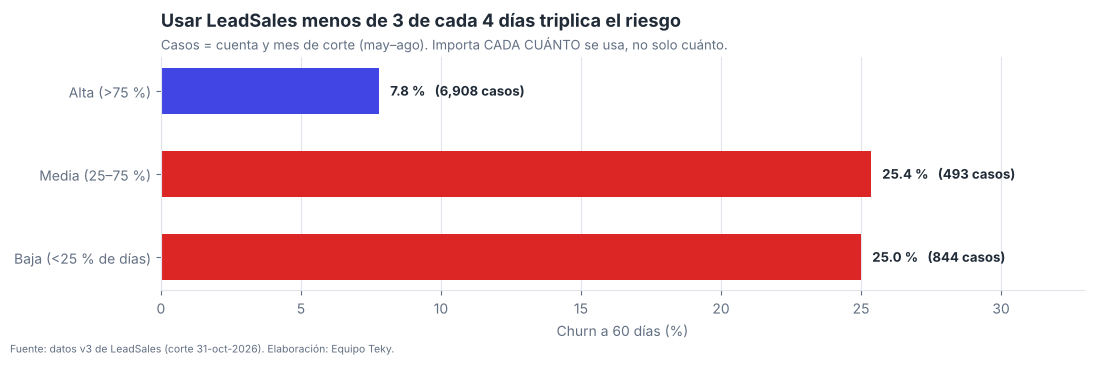

In [19]:
# =============================================================================
# V4 · Churn a 60 días según la proporción de días activos en el mes
# =============================================================================
niveles = ["Alta (>75 %)", "Media (25–75 %)", "Baja (<25 % de días)"]
t = con_desenlace.groupby("nivel_adopcion").agg(churn=("churn_60d", "mean"), casos=("account_id", "size")).reindex(niveles)
fig, ax = plt.subplots(figsize=(11, 3.6))
colores = [PALETA["marca"], PALETA["error"], PALETA["error"]]
barras = ax.barh(niveles, t["churn"] * 100, color=colores, height=0.55)
for b, (churn, casos) in zip(barras, t.to_numpy()):
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f"{churn * 100:.1f} %   ({int(casos):,} casos)",
            va="center", fontsize=9.5, fontweight="bold")
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Churn a 60 días (%)"); ax.set_xlim(0, t["churn"].max() * 130)
ax.set_title("Usar LeadSales menos de 3 de cada 4 días triplica el riesgo", pad=22)
subtitulo(ax, "Casos = cuenta y mes de corte (may–ago). Importa CADA CUÁNTO se usa, no solo cuánto.")
fuente(fig); plt.tight_layout(); plt.show()

### V5 · ¿Qué señal anticipa mejor? Uso, canal y contexto lado a lado

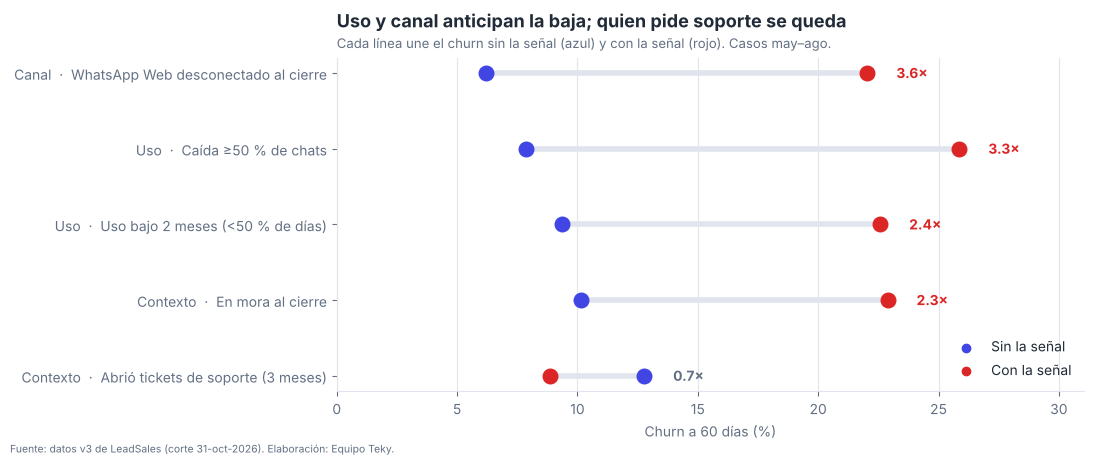

,Tipo,Señal,Casos con la señal (%),Churn con (%),Churn sin (%),Veces más
0,Contexto,Abrió tickets de soporte (3 meses),55.5,8.9,12.8,0.7
1,Contexto,En mora al cierre,3.4,22.9,10.2,2.3
2,Uso,Uso bajo 2 meses (<50 % de días),9.4,22.6,9.4,2.4
3,Uso,Caída ≥50 % de chats,11.8,25.9,7.9,3.3
4,Canal,WhatsApp Web desconectado al cierre,21.9,22.0,6.2,3.6


In [20]:
# =============================================================================
# V5 · Comparación de señales: churn con la señal vs sin la señal
# =============================================================================
SENALES = [
    ("Uso", "Caída ≥50 % de chats", "caida_50"),
    ("Uso", "Uso bajo 2 meses (<50 % de días)", "uso_bajo_dias_2m"),
    ("Canal", "WhatsApp Web desconectado al cierre", "wa_desconectado"),
    ("Contexto", "En mora al cierre", "mora"),
    ("Contexto", "Abrió tickets de soporte (3 meses)", "tickets_3m"),
]
filas = []
for tipo, nombre, col in SENALES:
    d = con_desenlace.dropna(subset=[col])
    con, sin = d.loc[d[col] == 1, "churn_60d"], d.loc[d[col] == 0, "churn_60d"]
    filas.append({"Tipo": tipo, "Señal": nombre, "Casos con la señal (%)": len(con) / len(d) * 100,
                  "Churn con (%)": con.mean() * 100, "Churn sin (%)": sin.mean() * 100,
                  "Veces más": con.mean() / sin.mean()})
senales = pd.DataFrame(filas).sort_values("Veces más", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 4.6))
for i, f in senales.iterrows():
    ax.plot([f["Churn sin (%)"], f["Churn con (%)"]], [i, i], color=PALETA["borde"], linewidth=4, zorder=1)
    ax.scatter(f["Churn sin (%)"], i, s=110, color=PALETA["marca"], zorder=2)
    ax.scatter(f["Churn con (%)"], i, s=110, color=PALETA["error"], zorder=2)
    ax.text(max(f["Churn con (%)"], f["Churn sin (%)"]) + 1.2, i, f"{f['Veces más']:.1f}×", va="center",
            fontsize=10, fontweight="bold", color=PALETA["error"] if f["Veces más"] >= 2 else PALETA["texto_sec"])
ax.set_yticks(range(len(senales)), [f"{t}  ·  {s}" for t, s in zip(senales["Tipo"], senales["Señal"])])
ax.scatter([], [], color=PALETA["marca"], label="Sin la señal"); ax.scatter([], [], color=PALETA["error"], label="Con la señal")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Churn a 60 días (%)"); ax.set_xlim(0, senales[["Churn con (%)", "Churn sin (%)"]].max().max() * 1.2)
ax.set_title("Uso y canal anticipan la baja; quien pide soporte se queda", pad=22)
subtitulo(ax, "Cada línea une el churn sin la señal (azul) y con la señal (rojo). Casos may–ago.")
ax.legend(loc="lower right"); fuente(fig); plt.tight_layout(); plt.show()
display(senales.round(1))

### V6 · ¿El canal suma algo al uso?

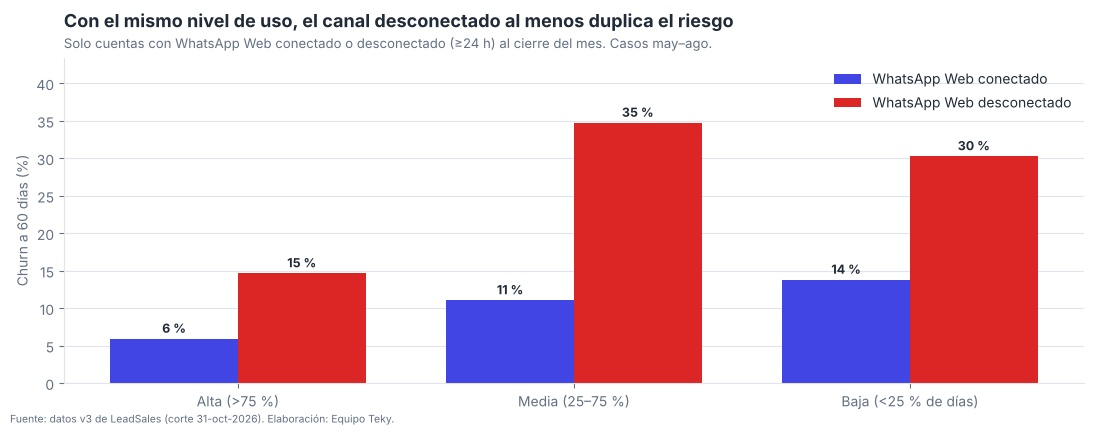

In [21]:
# =============================================================================
# V6 · Churn por nivel de días activos y estado de WhatsApp Web
# =============================================================================
d = con_desenlace[con_desenlace["estado_wa"].isin(["Conectado", "Desconectado"])]
t = d.groupby(["nivel_adopcion", "estado_wa"])["churn_60d"].mean().unstack().reindex(niveles) * 100
fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(len(t)); ancho = 0.38
b1 = ax.bar(x - ancho / 2, t["Conectado"], ancho, color=PALETA["marca"], label="WhatsApp Web conectado")
b2 = ax.bar(x + ancho / 2, t["Desconectado"], ancho, color=PALETA["error"], label="WhatsApp Web desconectado")
etiquetas_barras(ax, b1); etiquetas_barras(ax, b2)
ax.set_xticks(x, niveles); ax.set_ylabel("Churn a 60 días (%)"); ax.set_ylim(0, t.max().max() * 1.25)
ax.set_title("Con el mismo nivel de uso, el canal desconectado al menos duplica el riesgo", pad=22)
subtitulo(ax, "Solo cuentas con WhatsApp Web conectado o desconectado (≥24 h) al cierre del mes. Casos may–ago.")
ax.legend(loc="upper right"); fuente(fig); plt.tight_layout(); plt.show()

### V7 · ¿Cuándo aparece la señal? El uso antes de cancelar

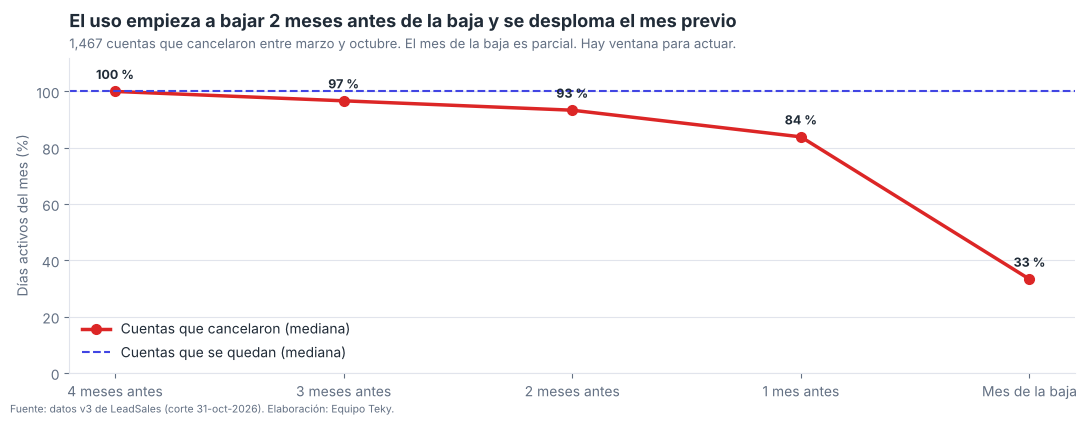

In [22]:
# =============================================================================
# V7 · Días activos (mediana) en los meses previos a la baja vs cuentas que se quedan
# =============================================================================
bajas = panel[panel["fecha_baja"].notna() & panel["estado_en_mes"].isin(["activa", "baja_este_mes"])].copy()
mes_baja = bajas["fecha_baja"].dt.to_period("M")
bajas["meses_antes"] = (mes_baja.dt.year - bajas["mes"].dt.year) * 12 + (mes_baja.dt.month - bajas["mes"].dt.month)
trayectoria = (bajas[bajas["meses_antes"].between(0, 4)].groupby("meses_antes")
               .agg(dias=("prop_dias_activos", "median"), cuentas=("account_id", "nunique")).sort_index(ascending=False))
referencia = con_desenlace.loc[con_desenlace["churn_60d"] == 0, "prop_dias_activos"].median() * 100

etiquetas = {4: "4 meses antes", 3: "3 meses antes", 2: "2 meses antes", 1: "1 mes antes", 0: "Mes de la baja"}
fig, ax = plt.subplots(figsize=(11, 4.2))
x = [etiquetas[m] for m in trayectoria.index]
ax.plot(x, trayectoria["dias"] * 100, color=PALETA["error"], linewidth=2.5, marker="o", markersize=7,
        label="Cuentas que cancelaron (mediana)")
ax.axhline(referencia, color=PALETA["marca"], linestyle="--", linewidth=1.5, label="Cuentas que se quedan (mediana)")
for xi, val in zip(x, trayectoria["dias"] * 100):
    ax.annotate(f"{val:.0f} %", (xi, val), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 112); ax.set_ylabel("Días activos del mes (%)")
ax.set_title("El uso empieza a bajar 2 meses antes de la baja y se desploma el mes previo", pad=22)
subtitulo(ax, f"{trayectoria['cuentas'].max():,} cuentas que cancelaron entre marzo y octubre. El mes de la baja es parcial. Hay ventana para actuar.")
ax.legend(loc="lower left"); fuente(fig); plt.tight_layout(); plt.show()

**Insight del acto 2 (respuesta a la pregunta directiva):** **sí, la baja adopción anticipa la cancelación**, y lo hace en dos frentes:

- **Funcionalidades (uso):** una caída de 50 % o más en los chats o usar la plataforma menos de 3 de cada 4 días **triplica** el churn a 60 días, en los cuatro meses analizados.
- **Canales:** tener WhatsApp Web desconectado al cierre del mes también se asocia con **~3.5 veces más churn**, y el efecto se mantiene aun entre cuentas con el mismo nivel de uso (V6). En el modelo de la Evidencia 4 la conexión no mejoró la predicción de forma consistente una vez que se conoce el uso, así que en el tablero el canal funciona como **señal de diagnóstico**: si una cuenta cae, revisar si es un problema técnico de conexión.
- **Contexto:** la mora duplica el riesgo y abrir tickets se asocia con **menos** churn (quien pide ayuda sigue comprometido).
- **Cuándo:** el uso empieza a caer **1 a 2 meses antes** de la baja (V7). Esa es la ventana para intervenir.

Son **asociaciones**, no causas: una caída no garantiza que la cuenta se vaya, pero sí dice a quién mirar primero.

## Acto 3 · ¿Quién está en riesgo hoy?
*Customer Success no puede llamar a todos. Necesita una lista ordenada y saber cuánto rinde revisar el 10, 20 o 30 % de la cartera.*

### V8 · ¿El score ordena bien? Churn real por decil de riesgo (prueba de agosto)

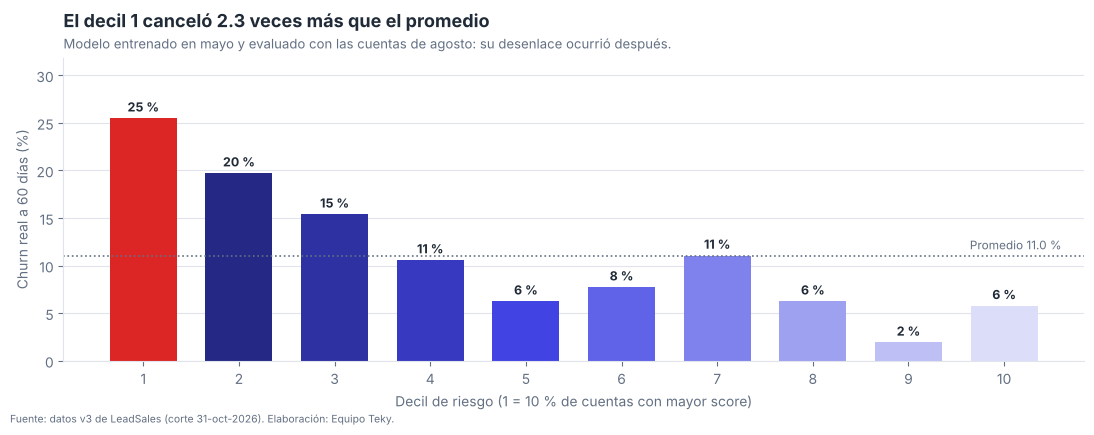

In [23]:
# =============================================================================
# V8 · Churn real (sep–oct) de las cuentas de agosto, por decil del score
# =============================================================================
t = prueba.groupby("decil_riesgo")["churn_60d"].agg(["mean", "size", "sum"])
fig, ax = plt.subplots(figsize=(11, 4.3))
colores = list(reversed(ESCALA_MARCA))       # decil 1 = el color más intenso
colores[0] = PALETA["error"]
barras = ax.bar(t.index.astype(str), t["mean"] * 100, color=colores, width=0.7)
etiquetas_barras(ax, barras, "{:.0f} %")
prevalencia = prueba["churn_60d"].mean() * 100
ax.axhline(prevalencia, color=PALETA["texto_sec"], linestyle=":", linewidth=1.2)
ax.text(9.6, prevalencia + 0.7, f"Promedio {prevalencia:.1f} %", ha="right", fontsize=8.5, color=PALETA["texto_sec"])
ax.set_xlabel("Decil de riesgo (1 = 10 % de cuentas con mayor score)"); ax.set_ylabel("Churn real a 60 días (%)")
ax.set_ylim(0, t["mean"].max() * 125)
ax.set_title(f"El decil 1 canceló {t['mean'].iloc[0] / prueba['churn_60d'].mean():.1f} veces más que el promedio", pad=22)
subtitulo(ax, "Modelo entrenado en mayo y evaluado con las cuentas de agosto: su desenlace ocurrió después.")
fuente(fig); plt.tight_layout(); plt.show()

### V9 · Cuánto rinde revisar el 10, 20 o 30 % de la cartera

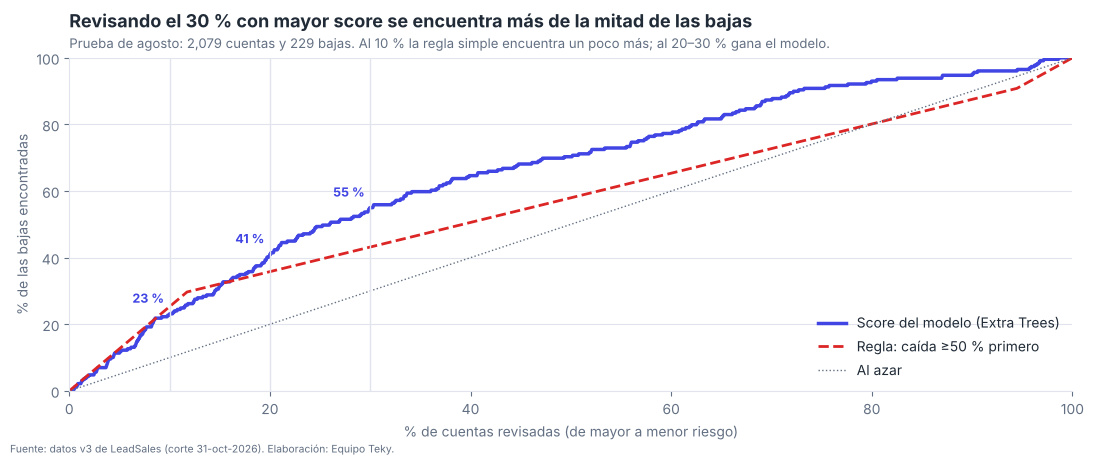

,Capacidad de CS,Cuentas a revisar,Bajas encontradas (modelo),Bajas encontradas (regla),Bajas al azar
0,10 %,208,53,58.0,22.9
1,20 %,416,94,82.0,45.8
2,30 %,624,126,98.9,68.7


In [24]:
# =============================================================================
# V9 · Curva de captura: % de bajas encontradas según el % de cuentas revisadas (agosto)
# =============================================================================
n, total_bajas = len(prueba), prueba["churn_60d"].sum()
fraccion = np.arange(1, n + 1) / n

orden = prueba.sort_values(["score", "account_id"], ascending=[False, True])
captura_modelo = orden["churn_60d"].cumsum().to_numpy() / total_bajas

# Regla simple: primero las cuentas con caída ≥50 %, luego las demás (dentro de cada grupo, al azar = promedio)
grupos = [prueba[prueba["caida_50"] == 1], prueba[prueba["caida_50"] == 0], prueba[prueba["caida_50"].isna()]]
captura_regla = np.concatenate([np.full(len(g), g["churn_60d"].mean()) for g in grupos]).cumsum() / total_bajas

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(fraccion * 100, captura_modelo * 100, color=PALETA["marca"], linewidth=2.5, label="Score del modelo (Extra Trees)")
ax.plot(fraccion * 100, captura_regla * 100, color=PALETA["error"], linewidth=2, linestyle="--", label="Regla: caída ≥50 % primero")
ax.plot([0, 100], [0, 100], color=PALETA["texto_sec"], linewidth=1, linestyle=":", label="Al azar")
filas_captura = []
for p in (10, 20, 30):
    k = int(np.ceil(p / 100 * n))
    m, r = captura_modelo[k - 1] * 100, captura_regla[k - 1] * 100
    filas_captura.append({"Capacidad de CS": f"{p} %", "Cuentas a revisar": k,
                          "Bajas encontradas (modelo)": int(round(m * total_bajas / 100)),
                          "Bajas encontradas (regla)": round(r * total_bajas / 100, 1),
                          "Bajas al azar": round(p / 100 * total_bajas, 1)})
    ax.axvline(p, color=PALETA["borde"], linewidth=1)
    ax.annotate(f"{m:.0f} %", (p, m), textcoords="offset points", xytext=(-4, 8), ha="right", fontsize=9,
                fontweight="bold", color=PALETA["marca"])
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("% de cuentas revisadas (de mayor a menor riesgo)"); ax.set_ylabel("% de las bajas encontradas")
ax.set_title("Revisando el 30 % con mayor score se encuentra más de la mitad de las bajas", pad=22)
subtitulo(ax, f"Prueba de agosto: {n:,} cuentas y {int(total_bajas)} bajas. Al 10 % la regla simple encuentra un poco más; al 20–30 % gana el modelo.")
ax.legend(loc="lower right"); fuente(fig); plt.tight_layout(); plt.show()
display(pd.DataFrame(filas_captura))

### V10 · ¿Por qué el modelo alerta a una cuenta?

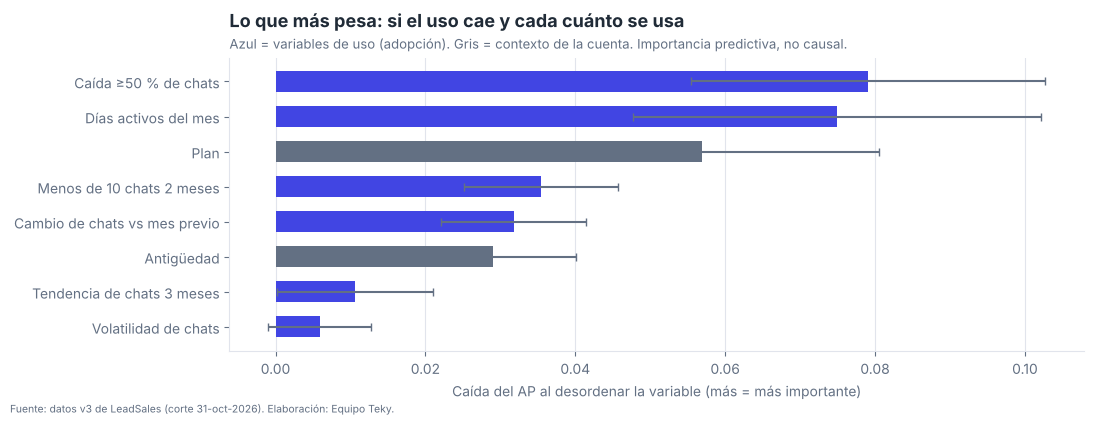

In [25]:
# =============================================================================
# V10 · Importancia por permutación: cuánto cae el AP si se desordena cada variable
# =============================================================================
NOMBRES_VARIABLES = {
    "caida_chats_50pct": "Caída ≥50 % de chats", "prop_dias_activos": "Días activos del mes",
    "plan": "Plan", "uso_bajo_2m": "Menos de 10 chats 2 meses", "cambio_relativo_chats": "Cambio de chats vs mes previo",
    "antiguedad_dias": "Antigüedad", "tendencia_chats_3m": "Tendencia de chats 3 meses",
    "volatilidad_chats_3m": "Volatilidad de chats", "media_chats_3m": "Chats promedio 3 meses",
    "mensajes_ultimo_mes": "Mensajes del mes", "chats_ultimo_mes": "Chats del mes",
}
top = importancia.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 4.2))
colores = [PALETA["marca"] if v != "plan" and v != "antiguedad_dias" else PALETA["texto_sec"] for v in top["variable"]]
ax.barh([NOMBRES_VARIABLES[v] for v in top["variable"]], top["caida_AP"], xerr=top["desv"], color=colores,
        height=0.6, error_kw={"ecolor": PALETA["texto_sec"], "capsize": 3})
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Caída del AP al desordenar la variable (más = más importante)")
ax.set_title("Lo que más pesa: si el uso cae y cada cuánto se usa", pad=22)
subtitulo(ax, "Azul = variables de uso (adopción). Gris = contexto de la cuenta. Importancia predictiva, no causal.")
fuente(fig); plt.tight_layout(); plt.show()

### V11 · La lista de hoy: cuentas prioritarias al 31 de octubre

In [26]:
# =============================================================================
# V11 · Tabla de las 15 cuentas con mayor score hoy (la lista que se descarga en el tablero)
# =============================================================================
lista_hoy = (hoy.sort_values(["score", "account_id"], ascending=[False, True])
             .assign(**{"Score (%)": lambda d: d["score"] * 100,
                        "Días activos (%)": lambda d: d["prop_dias_activos"] * 100,
                        "Caída ≥50 %": lambda d: d["caida_50"].map({1.0: "Sí", 0.0: "No"}).fillna("No medible")})
             .rename(columns={"account_id": "Account ID", "plan": "Plan", "segmento": "Perfil (K-Means)",
                              "n_chats": "Chats del mes", "variacion_chats_%": "Variación de chats (%)",
                              "estado_wa": "WhatsApp Web"})
             [["Account ID", "Plan", "Perfil (K-Means)", "Score (%)", "Chats del mes", "Variación de chats (%)",
               "Días activos (%)", "Caída ≥50 %", "WhatsApp Web"]])

estilo_tabla = (lista_hoy.head(15).style
                .format({"Score (%)": "{:.1f}", "Variación de chats (%)": "{:.0f}", "Días activos (%)": "{:.0f}"}, na_rep="—")
                .bar(subset=["Score (%)"], color=mezclar("#FFFFFF", PALETA["marca"], .45), vmin=0)
                .map(lambda v: f"color: {PALETA['error']}; font-weight: bold" if v in ("Sí", "Desconectado") else "",
                     subset=["Caída ≥50 %", "WhatsApp Web"])
                .set_table_styles([{"selector": "th", "props": f"background-color: {PALETA['texto']}; color: white; "
                                                               "font-weight: 600; padding: 6px"},
                                   {"selector": "td", "props": "padding: 5px 8px"}])
                .set_caption("Top 15 de 206 cuentas del decil 1 · corte 31-oct-2026 (sin desenlace todavía)")
                .hide(axis="index"))
display(estilo_tabla)
print(f"Del decil 1 de hoy: {(hoy.loc[hoy['decil_riesgo'] == 1, 'caida_50'] == 1).mean():.0%} tienen caída ≥50 % y "
      f"{(hoy.loc[hoy['decil_riesgo'] == 1, 'estado_wa'] == 'Desconectado').mean():.0%} tienen WhatsApp Web desconectado.")

Account ID,Plan,Perfil (K-Means),Score (%),Chats del mes,Variación de chats (%),Días activos (%),Caída ≥50 %,WhatsApp Web
WS-01083,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-01457,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Sin WhatsApp Web
WS-02766,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-00611,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-00969,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-01309,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-01316,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-01686,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-02469,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado
WS-03283,Basic,Uso muy bajo o nulo,33.3,0,—,0,No medible,Desconectado


Del decil 1 de hoy: 36% tienen caída ≥50 % y 47% tienen WhatsApp Web desconectado.


**Insight del acto 3:** el score de la Evidencia 4 **sí ordena el riesgo**: en la prueba de agosto el decil 1 canceló **2.3 veces más** que el promedio, y revisar el **30 % con mayor score encuentra el 55 % de las bajas** (126 de 229, contra 69 al azar). Con capacidad del 10 %, la regla simple de "caída ≥50 %" encuentra un poco más (58 contra 53 bajas) y es más fácil de explicar; a partir del 20 %, el modelo rinde más (94 contra 82, y 126 contra 99). Hoy hay **206 cuentas** en el decil 1: esa es la lista de trabajo de este mes.

## Acto 4 · ¿Qué hacemos?
*Saber quién está en riesgo no basta: cada perfil de cuenta necesita una acción distinta.*

### V12 · Los tres perfiles de adopción (K-Means) y su riesgo

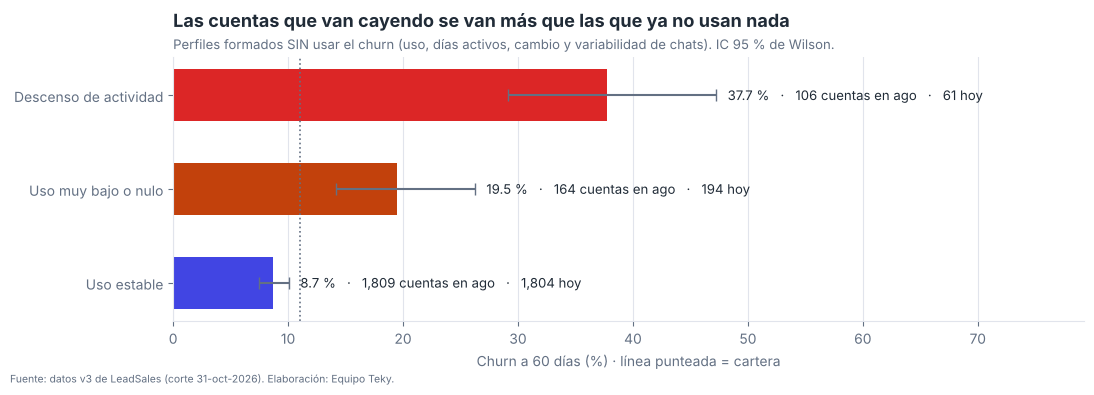

In [27]:
# =============================================================================
# V12 · Churn a 60 días por perfil de K-Means (agosto), con intervalo de confianza de Wilson
# =============================================================================
orden_seg = ["Uso estable", "Uso muy bajo o nulo", "Descenso de actividad"]
t = seg_agosto.groupby("segmento")["churn_60d"].agg(["sum", "size"]).reindex(orden_seg)
t["churn"] = t["sum"] / t["size"] * 100
ic = np.array([wilson(b, n) for b, n in zip(t["sum"], t["size"])]) * 100
cuentas_hoy = hoy["segmento"].value_counts().reindex(orden_seg)

fig, ax = plt.subplots(figsize=(11, 3.9))
barras = ax.barh(orden_seg, t["churn"], color=[COLOR_SEGMENTO[s] for s in orden_seg], height=0.55,
                 xerr=[t["churn"] - ic[:, 0], ic[:, 1] - t["churn"]], error_kw={"ecolor": PALETA["texto_sec"], "capsize": 4})
for b, churn, n_ago, n_hoy, sup in zip(barras, t["churn"], t["size"], cuentas_hoy, ic[:, 1]):
    ax.text(sup + 1, b.get_y() + b.get_height() / 2,
            f"{churn:.1f} %   ·   {n_ago:,} cuentas en ago   ·   {n_hoy:,} hoy", va="center", fontsize=9.5)
ax.axvline(prueba["churn_60d"].mean() * 100, color=PALETA["texto_sec"], linestyle=":", linewidth=1.2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(0, ic[:, 1].max() + 32); ax.set_xlabel("Churn a 60 días (%) · línea punteada = cartera")
ax.set_title("Las cuentas que van cayendo se van más que las que ya no usan nada", pad=22)
subtitulo(ax, "Perfiles formados SIN usar el churn (uso, días activos, cambio y variabilidad de chats). IC 95 % de Wilson.")
fuente(fig); plt.tight_layout(); plt.show()

### V13 · ¿Qué dicen al irse? Motivo de cancelación por perfil

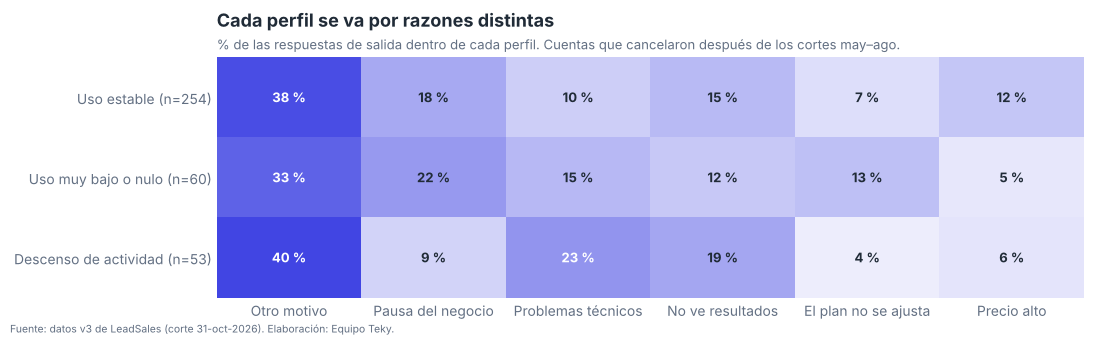

In [28]:
# =============================================================================
# V13 · Motivo de cancelación (encuesta de salida) de las cuentas de agosto que cancelaron, por perfil
# =============================================================================
NOMBRES_MOTIVOS = {"H2_technical_issues": "Problemas técnicos", "H4_lack_of_results": "No ve resultados",
                   "H5_high_pricing": "Precio alto", "H6_plan_fit": "El plan no se ajusta",
                   "H8_business_pause": "Pausa del negocio", "OTHER": "Otro motivo"}
ultima_respuesta = (cancelaciones.sort_values("fecha").drop_duplicates("account_id", keep="last")
                    .assign(motivo=lambda d: d["motivo_normalizado"].map(NOMBRES_MOTIVOS).fillna("Otro motivo")))
# Cuentas que cancelaron después de algún corte may–ago (se toma su último corte antes de la baja)
canceladas = (con_desenlace[con_desenlace["churn_60d"] == 1].sort_values("corte")
              .drop_duplicates("account_id", keep="last").copy())
# Perfil de cada cuenta cancelada: se asigna con su ventana de 3 meses y los centroides de agosto
canceladas["segmento"] = asignar_segmento(canceladas)
canceladas = canceladas.merge(ultima_respuesta[["account_id", "motivo"]], on="account_id", how="inner")

matriz = pd.crosstab(canceladas["segmento"], canceladas["motivo"], normalize="index").reindex(orden_seg) * 100
orden_motivos = matriz.mean().sort_values(ascending=False).index
matriz = matriz[orden_motivos]
n_por_seg = canceladas["segmento"].value_counts().reindex(orden_seg)

fig, ax = plt.subplots(figsize=(11, 3.4))
from matplotlib.colors import LinearSegmentedColormap
mapa = LinearSegmentedColormap.from_list("marca", ["#FFFFFF", mezclar("#FFFFFF", PALETA["marca"], .5), PALETA["marca"]])
im = ax.imshow(matriz.to_numpy(), cmap=mapa, aspect="auto", vmin=0, vmax=matriz.to_numpy().max())
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.iat[i, j]
        ax.text(j, i, f"{v:.0f} %", ha="center", va="center", fontsize=9.5, fontweight="bold",
                color="white" if v > matriz.to_numpy().max() * .55 else PALETA["texto"])
ax.set_xticks(range(len(orden_motivos)), orden_motivos)
ax.set_yticks(range(len(orden_seg)), [f"{s} (n={n})" for s, n in zip(orden_seg, n_por_seg)])
ax.grid(False); ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Cada perfil se va por razones distintas", pad=22)
subtitulo(ax, "% de las respuestas de salida dentro de cada perfil. Cuentas que cancelaron después de los cortes may–ago.")
fuente(fig); plt.tight_layout(); plt.show()

### V14 · Matriz de acción para Customer Success

In [29]:
# =============================================================================
# V14 · Qué hacer con cada perfil (cuentas de hoy) y cuándo
# =============================================================================
acciones = {
    "Descenso de actividad": ("Primera prioridad. Llamada de diagnóstico: \"¿qué cambió en tu operación?\"; "
                              "revisar si WhatsApp Web está desconectado (solución técnica rápida) y ofrecer capacitación.",
                              "Al cierre de cada mes"),
    "Uso muy bajo o nulo": ("Reactivación o ajuste de plan antes de su renovación; no es la urgencia principal "
                            "(paga por costumbre).", "Antes de la renovación"),
    "Uso estable": ("Seguimiento normal. Solo atender si su score entra al decil 1 o desconecta WhatsApp Web.",
                    "Monitoreo mensual"),
}
matriz_accion = pd.DataFrame([{
    "Perfil": s,
    "Churn 60 d (ago)": f"{seg_agosto.loc[seg_agosto['segmento'] == s, 'churn_60d'].mean() * 100:.1f} %",
    "Cuentas hoy": int((hoy["segmento"] == s).sum()),
    "En decil 1 hoy": int(((hoy["segmento"] == s) & (hoy["decil_riesgo"] == 1)).sum()),
    "Con WhatsApp Web desconectado hoy": int(((hoy["segmento"] == s) & (hoy["estado_wa"] == "Desconectado")).sum()),
    "Acción sugerida": acciones[s][0],
    "Cuándo": acciones[s][1],
} for s in ["Descenso de actividad", "Uso muy bajo o nulo", "Uso estable"]])

display(matriz_accion.style
        .map(lambda v: f"color: white; background-color: {COLOR_SEGMENTO[v]}; font-weight: bold", subset=["Perfil"])
        .set_table_styles([{"selector": "th", "props": f"background-color: {PALETA['texto']}; color: white; padding: 6px"},
                           {"selector": "td", "props": "padding: 6px 8px; vertical-align: top"}])
        .hide(axis="index"))

Perfil,Churn 60 d (ago),Cuentas hoy,En decil 1 hoy,Con WhatsApp Web desconectado hoy,Acción sugerida,Cuándo
Descenso de actividad,37.7 %,61,26,39,"Primera prioridad. Llamada de diagnóstico: ""¿qué cambió en tu operación?""; revisar si WhatsApp Web está desconectado (solución técnica rápida) y ofrecer capacitación.",Al cierre de cada mes
Uso muy bajo o nulo,19.5 %,194,138,96,Reactivación o ajuste de plan antes de su renovación; no es la urgencia principal (paga por costumbre).,Antes de la renovación
Uso estable,8.7 %,1804,42,252,Seguimiento normal. Solo atender si su score entra al decil 1 o desconecta WhatsApp Web.,Monitoreo mensual


**Insight del acto 4:** los perfiles cambian la acción, no solo la urgencia. Las cuentas en **descenso de actividad** cancelan **más de 4 veces más** que las estables y son las más accionables: todavía usan LeadSales, pero algo cambió. Al irse, mencionan **problemas técnicos** con más frecuencia (23 %) que las estables (10 %), lo que refuerza revisar primero la conexión del canal. Las de **uso nulo** cancelan menos de lo que parece porque muchas son cuentas antiguas que pagan por costumbre: su momento es la renovación. Las estables solo se atienden si su score o su canal encienden una alerta.

---
# 5. Propuestas de visualizaciones y modificaciones futuras

El tablero está pensado para crecer. Estas son dos visualizaciones adicionales ya codificadas y una lista de modificaciones posibles.

### P1 · ¿Cómo se mueven las cuentas entre perfiles? (mayo → agosto)

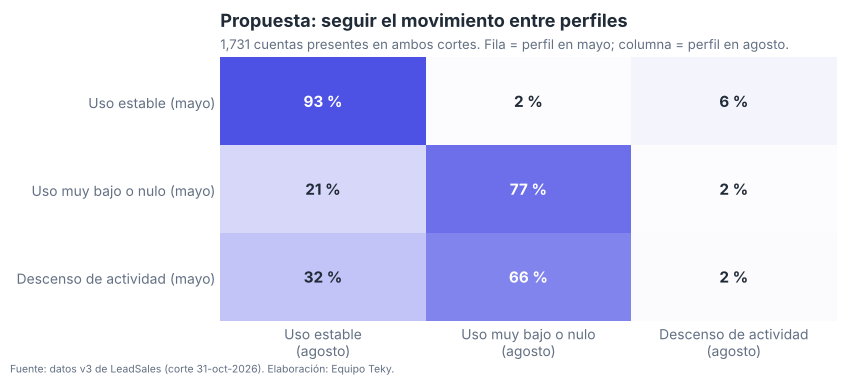

De las cuentas estables en mayo, 5.7 % pasó a 'Descenso de actividad' en agosto.
De las cuentas en descenso en mayo, 66 % terminó con uso muy bajo o nulo en agosto.


In [30]:
# =============================================================================
# P1 · Matriz de transición de perfiles: ventana mar–may vs ventana jun–ago (mismos centroides)
# =============================================================================
seg_mayo = desarrollo.copy()
seg_mayo["segmento"] = asignar_segmento(seg_mayo)
transicion = seg_mayo[["account_id", "segmento"]].merge(seg_agosto[["account_id", "segmento"]], on="account_id",
                                                         suffixes=("_mayo", "_agosto"))
matriz_t = pd.crosstab(transicion["segmento_mayo"], transicion["segmento_agosto"], normalize="index") \
             .reindex(index=orden_seg, columns=orden_seg).fillna(0) * 100

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.imshow(matriz_t.to_numpy(), cmap=mapa, vmin=0, vmax=100, aspect="auto")
for i in range(3):
    for j in range(3):
        v = matriz_t.iat[i, j]
        ax.text(j, i, f"{v:.0f} %", ha="center", va="center", fontsize=11, fontweight="bold",
                color="white" if v > 55 else PALETA["texto"])
ax.set_xticks(range(3), [f"{s}\n(agosto)" for s in orden_seg]); ax.set_yticks(range(3), [f"{s} (mayo)" for s in orden_seg])
ax.grid(False); ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Propuesta: seguir el movimiento entre perfiles", pad=22)
subtitulo(ax, f"{len(transicion):,} cuentas presentes en ambos cortes. Fila = perfil en mayo; columna = perfil en agosto.")
fuente(fig); plt.tight_layout(); plt.show()
estable_a_descenso = matriz_t.loc["Uso estable", "Descenso de actividad"]
print(f"De las cuentas estables en mayo, {estable_a_descenso:.1f} % pasó a 'Descenso de actividad' en agosto.")
print(f"De las cuentas en descenso en mayo, {matriz_t.loc['Descenso de actividad', 'Uso muy bajo o nulo']:.0f} % "
      "terminó con uso muy bajo o nulo en agosto.")

**Por qué agregarla:** el descenso de actividad es un estado de **paso**: dos de cada tres cuentas que iban cayendo en mayo terminaron sin uso en agosto. Ver este movimiento mes a mes permitiría intervenir justo cuando una cuenta estable empieza a caer.

### P2 · ¿El riesgo cambia según el plan? (mapa de calor plan × días activos)

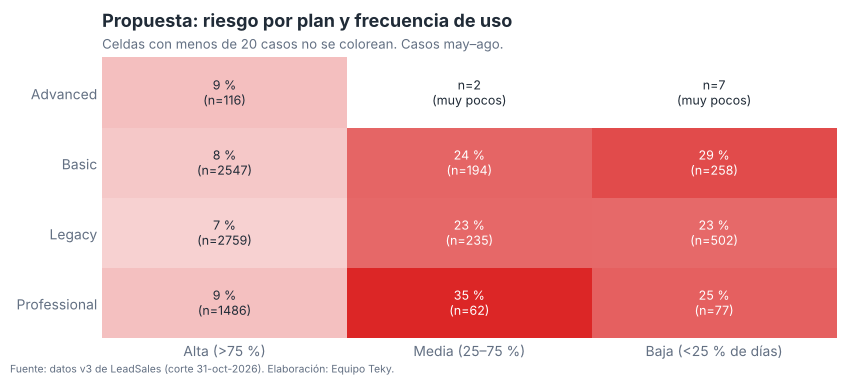

In [31]:
# =============================================================================
# P2 · Churn a 60 días por plan y nivel de días activos (casos may–ago)
# =============================================================================
t = con_desenlace.pivot_table(index="plan", columns="nivel_adopcion", values="churn_60d", aggfunc="mean").reindex(columns=niveles) * 100
n = con_desenlace.pivot_table(index="plan", columns="nivel_adopcion", values="churn_60d", aggfunc="size").reindex(columns=niveles)
t = t.where(n >= 20)          # con menos de 20 casos la tasa no es confiable: no se colorea
mapa_riesgo = LinearSegmentedColormap.from_list("riesgo", ["#FFFFFF", mezclar("#FFFFFF", PALETA["error"], .55), PALETA["error"]])
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.imshow(t.to_numpy(), cmap=mapa_riesgo, vmin=0, vmax=np.nanmax(t.to_numpy()), aspect="auto")
for i in range(t.shape[0]):
    for j in range(t.shape[1]):
        v, casos = t.iat[i, j], n.iat[i, j]
        texto = f"n={int(casos)}\n(muy pocos)" if pd.isna(v) else f"{v:.0f} %\n(n={int(casos)})"
        ax.text(j, i, texto, ha="center", va="center", fontsize=9,
                color="white" if (not pd.isna(v) and v > np.nanmax(t.to_numpy()) * .6) else PALETA["texto"])
ax.set_xticks(range(len(niveles)), niveles); ax.set_yticks(range(len(t.index)), t.index)
ax.grid(False); ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Propuesta: riesgo por plan y frecuencia de uso", pad=22)
subtitulo(ax, "Celdas con menos de 20 casos no se colorean. Casos may–ago.")
fuente(fig); plt.tight_layout(); plt.show()

### P3 · Modificaciones posibles al tablero

| Propuesta | Qué agrega | Qué se necesita |
|---|---|---|
| **Pantalla "Perfil 360"** al hacer clic en una cuenta de la lista | Historial de uso, canal, mora, tickets y motivo de una sola cuenta | Ya está en el sitemap; en Dash, un callback con `clickData` o `active_cell` |
| **Alerta automática mensual** | Correo o mensaje por Leadbot a las cuentas en descenso | Correr el score al cierre de cada mes |
| **Score en vivo en el tablero** | Que la lista de prioridad se recalcule sola | Guardar el modelo entrenado (`joblib`) y cargarlo en Dash |
| **Seguimiento del piloto A/B** | KPI de negocio: retención a 60 días de cuentas contactadas vs no contactadas | Dividir al azar el top del score cada mes |
| **Más canales** (Instagram, Facebook, API) | Completar la parte de "canales" de la pregunta | Que LeadSales corrija las desconexiones faltantes y los borrados masivos |
| **Regla para cuentas nuevas (onboarding)** | Cubrir a las cuentas con menos de 3 meses, que hoy no tienen score | Calibrar un umbral de días activos en el primer mes |
| **Tendencia del modelo** | AP, precisión@K y lift por corte, para ver si el modelo se degrada | Guardar las métricas de cada mes |

In [32]:
# =============================================================================
# Salida para el tablero de Dash: score y perfil de las cuentas de HOY
# =============================================================================
salida = hoy[["account_id", "corte", "plan", "segmento", "score", "decil_riesgo", "caida_50", "prop_dias_activos",
              "n_chats", "variacion_chats_%", "estado_wa"]].copy()
salida["score"] = salida["score"].round(4)
destino = CARPETA_LOCAL if CARPETA_LOCAL.exists() else Path(".")
salida.to_csv(destino / "scores_modelo_hoy.csv", index=False)
print(f"Guardado {destino / 'scores_modelo_hoy.csv'}: {len(salida):,} cuentas")

Guardado datos/scores_modelo_hoy.csv: 2,059 cuentas


---
# 6. Conclusiones

### La historia que cuenta el tablero
1. **Hay un problema constante:** cada mes se va ~7 % de la cartera y 1 de cada 10 cuentas maduras cancela en 60 días.
2. **La baja adopción lo anticipa:** caídas de uso, pocos días activos y WhatsApp Web desconectado triplican el riesgo, y la señal aparece 1 a 2 meses antes de la baja.
3. **Se puede priorizar:** el score de la Evidencia 4 concentra el riesgo en el decil 1 y, revisando el 30 % de la cartera, encuentra el 55 % de las bajas.
4. **Cada perfil pide una acción:** las cuentas en descenso son la urgencia; las de uso nulo, la renovación; las estables, el monitoreo.

### Respuesta a la pregunta directiva
> **Sí: la baja adopción anticipa la cancelación.** La forma de identificarla es vigilar cada mes la **caída de chats** y los **días activos** (adopción de funcionalidades) y la **conexión de WhatsApp Web** (adopción de canales), ordenar las cuentas con el score del modelo y actuar según su perfil.

### Limitaciones que el tablero declara
- Son **asociaciones**, no causas; medir si contactar evita la baja requiere el piloto A/B.
- El modelo se probó en **un solo corte** (agosto) y su discriminación es moderada (AP ≈ 0.20, ROC-AUC ≈ 0.68): sirve para **ordenar**, no para afirmar que una cuenta se va.
- Solo se usa WhatsApp Web como canal; los datos de Instagram, Facebook y la API no son confiables todavía.
- Las cuentas con menos de 3 meses de historial no tienen score.